<p class="lead">This notebook expands the fifth unit of the course. The lecture slides are a map; this text is the territory. Units 2–4 trained models on data whose answer was known: every aspirate carried a biopsy result, every image a diagnosis, and the quality of a model was the agreement between its predictions and those labels. This unit removes the labels. What remains is a data matrix and three questions that can be asked of it without any answer key: <em>do the cases fall into groups?</em> (clustering — k-means and hierarchical clustering), <em>can the many measured features be summarised by a few?</em> (dimensionality reduction — principal component analysis), and <em>can mixed signals be separated into their sources?</em> (blind source separation — independent component analysis). Each method is derived, traced by hand on a paper-sized example, confirmed in numpy and scikit-learn, exercised on the breast-cancer data that recur throughout the course, and pushed until it fails, because knowing <em>when</em> a method fails is the difference between using it and being used by it. Laboratory 3 applies these four methods; Workshop 3 is a questionnaire on them; this text is the preparation for both.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Define unsupervised learning and distinguish clustering, dimensionality reduction and density estimation; explain what a clustering result can and cannot tell you in the absence of labels.</li>
<li>State the k-means objective (within-cluster sum of squares), execute Lloyd's algorithm by hand on a small dataset, and explain why it converges to a local, not a global, minimum.</li>
<li>Describe the main variants of k-means (fuzzy c-means, k-medoids, mini-batch, k-means++, spherical) and say when each is appropriate.</li>
<li>Choose the number of clusters with the elbow method, the silhouette and the gap statistic, and name the situations in which k-means fails (unequal sizes, non-convex shapes, unscaled features).</li>
<li>Execute agglomerative hierarchical clustering by hand, state the single, complete, average and Ward linkage rules, read a dendrogram, cut it, and compute the cophenetic correlation.</li>
<li>Derive principal component analysis as variance maximisation and as minimum reconstruction error; compute the principal components of a small dataset by hand from the covariance matrix; interpret a scree plot, loadings and a biplot; explain why standardisation comes first.</li>
<li>Explain independent component analysis as blind source separation driven by non-Gaussianity, run FastICA, and use it to remove an artefact from a multichannel physiological recording.</li>
<li>Evaluate an unsupervised result with internal and external indices and recognise circular validation.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Each code cell is short and commented. Run it, read its output, then read the paragraph that interprets the output. Exercises (green boxes) ask you to modify the cell above them and re-run; they are the fastest way to learn. Blue boxes carry key ideas, orange boxes carry common misconceptions, and purple boxes connect this unit to other units or to the bioinformatics course (BGM324). The notebook uses only <code>numpy</code>, <code>pandas</code>, <code>matplotlib</code>, <code>scipy</code> and <code>scikit-learn</code>, all pre-installed in Google Colab; no data is downloaded. Three algorithms are traced by hand (k-means in Section 2.4, agglomerative clustering in Section 3.3, PCA in Section 4.2) before code confirms them. The vocabulary of Supplement S1 — train/test split, cross-validation, accuracy, leakage — is assumed and used without re-derivation.</p></div>

In [1]:
# Setup: libraries used throughout the notebook. Random seeds are fixed so that every
# number quoted in the text is reproducible.
import warnings; warnings.filterwarnings("ignore")      # keep the outputs readable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from sklearn import datasets
from sklearn.preprocessing import StandardScaler

np.random.seed(0)
pd.set_option("display.width", 130); pd.set_option("display.max_columns", 12)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN, GREY, PURPLE = "#2b5d9b", "#d2691e", "#3a7d44", "#7f7f7f", "#7b4f9d"
PALETTE = [BLUE, ORANGE, GREEN, PURPLE, "#b5a000", "#9b2b2b", GREY]
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.4.6 | pandas 3.0.3 | scipy 1.17.1 | scikit-learn 1.9.0


## 1. Learning without labels

### 1.1 What changes when the labels are removed

In every unit so far, the training sample was a pair $(\mathbf{X}, \mathbf{y})$: a data matrix of $n$ cases described by $p$ features, and a vector of $n$ known answers. The learning algorithm adjusted a model until its outputs agreed with $\mathbf{y}$, and Supplement S1 explained how to measure that agreement on cases the model had not seen. This is <strong>supervised</strong> learning, named after the teacher who supplies the answers.

<strong>Unsupervised learning</strong> starts from $\mathbf{X}$ alone. There is no $\mathbf{y}$, hence no error to minimise against a truth, hence no accuracy, sensitivity or ROC curve. What the algorithm has instead is the <em>structure</em> of $\mathbf{X}$: which cases resemble which, which features vary together, which directions in feature space carry most of the variation. The three main tasks are:

| Task | Question asked of $\mathbf{X}$ | Output | Methods in this unit |
|---|---|---|---|
| **Clustering** | Do the $n$ cases fall into groups of mutually similar cases? | A partition of the rows (a label per case, invented by the algorithm) | k-means (Section 2), hierarchical clustering (Section 3), Gaussian mixtures, DBSCAN, spectral clustering (Section 6) |
| **Dimensionality reduction** | Can the $p$ features be replaced by $q \ll p$ new ones that keep most of the information? | A transformation of the columns (new coordinates per case) | PCA (Section 4), ICA (Section 5); t-SNE and UMAP for visualisation (Section 4.7) |
| **Density estimation** | What is the probability distribution that generated the rows? | A model $p(\mathbf{x})$ that assigns a probability density to any point | Gaussian mixture models (Section 6); the histograms and kernel density estimates of Unit 3 |

The three are related — a mixture model is a density estimate whose components are clusters; clustering is the most aggressive dimensionality reduction, from $p$ features to one categorical variable — and all look for a <em>compact description</em> of the data: a few centroids, a few axes, a few components. The compactness is what makes the description useful and what makes it lossy.

### 1.2 What unsupervised learning can and cannot tell you

An unsupervised method always returns an answer. Asked for three clusters, k-means returns three clusters whether the data have three groups, two, or none at all; asked for two components, PCA returns two whether they explain 95 % or 15 % of the variance. This is the central methodological difficulty of the unit: <strong>the output cannot be validated against a truth, because no truth was supplied</strong>. What can be done, and what Section 7 develops, is to measure internal properties (are the clusters compact and separated? how much variance do the components retain?), to measure stability (does the result change when the sample is perturbed?), and — when labels exist but were hidden, as in every example of this notebook — to compare the result with them <em>after the fact</em>, as an external check that was never available to the algorithm.

The last point deserves care. The breast-cancer data<sup class="c"><a href="#r1">[1]</a></sup> carry a biopsy label, and this notebook will hide it, cluster the 30 nuclear features, and then ask whether the clusters coincide with the diagnosis. When they do, the temptation is to say that k-means "diagnosed" the tumours. It did not: it found that malignant and benign nuclei differ enough in size and shape that the two most compact groups in the data happen to separate them. Had the dominant source of variation been, say, the laboratory that prepared the slide, k-means would have found laboratories instead, with equal confidence. Unit 2 made this correction once and it is repeated here because the error is common in the applied literature: <em>clustering discovers structure; it does not discover the structure you were hoping for</em>.<sup class="c"><a href="#r2">[2]</a></sup>

Why, then, learn without labels? Because labels are expensive (a biopsy, a pathologist's hour, a ten-year follow-up), because they may not exist yet (a disease whose subtypes are unknown — Section 8), because the question may be exploratory, and because preprocessing a supervised problem — reducing 30 correlated features to 10 uncorrelated ones — is itself unsupervised. Clustering alone has a literature of thousands of algorithms;<sup class="c"><a href="#r3">[3]</a></sup> this unit presents the two families that account for most of its use, and the two decompositions that account for most of dimensionality reduction.

### 1.3 The running example, with the labels hidden

The cell below loads the Wisconsin Diagnostic Breast Cancer data, standardises the 30 features (Section 2.7 shows what happens without this step), and sets the labels aside in a variable that no algorithm will see until Section 2.8. The figure plots two features as the algorithm sees them — unlabelled — and, beside them, as a supervised method would.

Data matrix: (569, 30) | after standardisation: column means ~ 0.0 , column standard deviations = 1.0
Range of raw features: smallest max = 0.03 (fractal dimension error), largest max = 4254.0 (worst area)


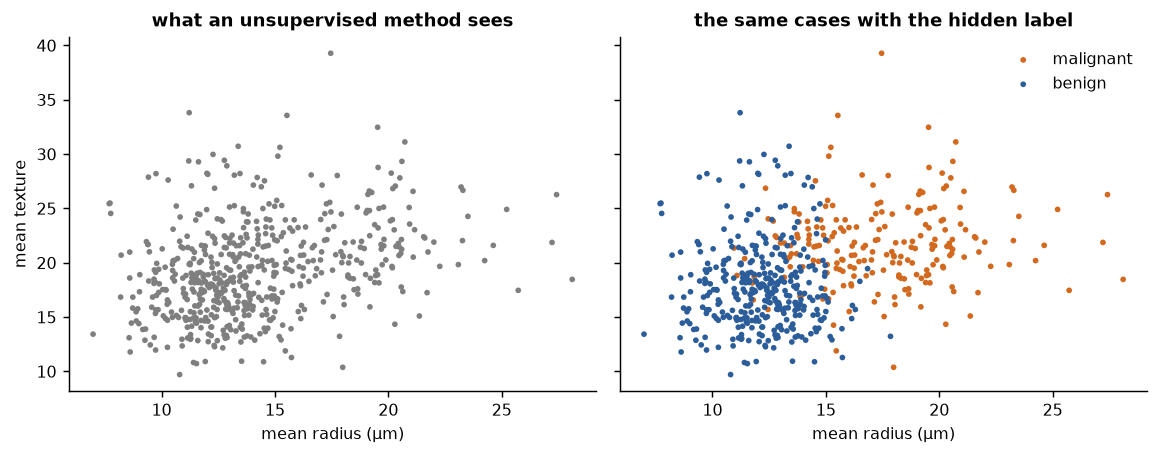

In [2]:
# The running example: 569 aspirates x 30 nuclear features. The label is hidden from every algorithm.
cancer = datasets.load_breast_cancer(as_frame=True)
X_df = cancer.data
y_hidden = cancer.target.to_numpy()                   # 0 = malignant, 1 = benign; used only to check results AFTER clustering
X_raw = X_df.to_numpy()
X_std = StandardScaler().fit_transform(X_raw)        # every feature to mean 0, standard deviation 1
print("Data matrix:", X_raw.shape, "| after standardisation: column means ~", np.abs(X_std.mean(0)).max().round(12),
      ", column standard deviations =", X_std.std(0).round(6).min())
print("Range of raw features: smallest max =", X_df.max().min().round(3), f"({X_df.max().idxmin()}), largest max =",
      X_df.max().max().round(1), f"({X_df.max().idxmax()})")

f1, f2 = "mean radius", "mean texture"
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
axes[0].scatter(X_df[f1], X_df[f2], s=10, color=GREY, edgecolor="none")
axes[0].set_title("what an unsupervised method sees"); axes[0].set_xlabel(f1 + " (µm)"); axes[0].set_ylabel(f2)
for c, col, name in [(0, ORANGE, "malignant"), (1, BLUE, "benign")]:
    axes[1].scatter(X_df[f1][y_hidden == c], X_df[f2][y_hidden == c], s=10, color=col, edgecolor="none", label=name)
axes[1].set_title("the same cases with the hidden label"); axes[1].set_xlabel(f1 + " (µm)"); axes[1].legend(frameon=False)
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> Left: 569 aspirates described by mean nuclear radius and mean texture, as an unsupervised algorithm receives them — one grey cloud, denser at the lower left, with a diffuse tail towards larger radii. Right: the same points coloured by the biopsy result that has been hidden. There is a visible tendency — malignant nuclei are larger — but no gap between the groups; whether a clustering algorithm will split the cloud along the diagnosis, along some other direction, or at all, is exactly the question of this unit.</p>

The printout also records why standardisation was applied before anything else: the raw features range from a maximum below 1 (the fractal-dimension and smoothness features are dimensionless ratios) to a maximum above 4,000 (<em>worst area</em>, in µm²). Every method in this unit is built on Euclidean distances or on variances, and both are dominated by whichever feature has the largest numbers. After standardisation each column has mean 0 and standard deviation 1, so each feature contributes on equal terms. Section 2.7 and Section 4.3 show, with the same data, what happens when this step is skipped.

## 2. k-Means

### 2.1 Definition: the within-cluster sum of squares

Given $n$ points $\mathbf{x}_1, \dots, \mathbf{x}_n \in \mathbb{R}^p$ and a chosen number of clusters $k$, k-means seeks a partition of the points into $k$ disjoint sets $C_1, \dots, C_k$ and $k$ centroids $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_k$ that minimise the <strong>within-cluster sum of squares</strong> (WCSS; scikit-learn calls it the <em>inertia</em>):

<div class="eq">$$J(C, \boldsymbol{\mu}) = \sum_{j=1}^{k} \sum_{\mathbf{x}_i \in C_j} \lVert \mathbf{x}_i - \boldsymbol{\mu}_j \rVert_2^2$$
<span class="where">where $\lVert \mathbf{x}_i - \boldsymbol{\mu}_j \rVert_2^2$ is the squared Euclidean distance between a point and the centroid of the cluster it belongs to. For a fixed partition, $J$ is minimised when each $\boldsymbol{\mu}_j$ is the arithmetic mean of the points in $C_j$ — hence the name — and for fixed centroids, $J$ is minimised when each point is assigned to its nearest centroid.</span></div>

The objective has a second reading that explains what k-means is good at. Expanding the squares, $J$ is proportional to the sum over clusters of the <em>total pairwise squared distance within the cluster</em> divided by the cluster size, so k-means is looking for groups of points that are mutually close, measured in squared Euclidean distance. It follows that the method prefers clusters that are round (isotropic), of similar spread and of similar size — the three preferences that Section 2.7 turns into failure modes.

Finding the partition that minimises $J$ exactly is NP-hard, even for $k = 2$ in general dimension, so every practical algorithm is a heuristic that finds a <em>local</em> minimum. The name "k-means" was coined by MacQueen in 1967 for an online version of the procedure;<sup class="c"><a href="#r4">[4]</a></sup> the batch algorithm that everyone uses was described by Lloyd in a 1957 Bell Laboratories report on pulse-code modulation, published only in 1982,<sup class="c"><a href="#r5">[5]</a></sup> and is known as <strong>Lloyd's algorithm</strong>. Section 2.3 states it; Section 2.4 executes it by hand.

### 2.2 Types of k-means

The textbook algorithm has several variants, each addressing one of its limitations. The lecture lists them under "types"; one paragraph each, with the situation that calls for it.

**Hard k-means (the standard).** Each point belongs to exactly one cluster. This is what <code>sklearn.cluster.KMeans</code> implements and what the rest of this section uses. Use it when the clusters are expected to be compact, roughly spherical and of comparable size, and when a crisp partition is what is needed.

**Soft or fuzzy k-means (fuzzy c-means).** Each point receives a <em>membership degree</em> $u_{ij} \in [0, 1]$ in every cluster, with $\sum_j u_{ij} = 1$, and the objective becomes $\sum_i \sum_j u_{ij}^m \lVert \mathbf{x}_i - \boldsymbol{\mu}_j \rVert^2$ with a fuzziness exponent $m > 1$ (usually 2). Centroids are membership-weighted means. Bezdek's 1981 monograph is the standard reference.<sup class="c"><a href="#r6">[6]</a></sup> Use it when points near a boundary should not be forced into one group — tissue segmentation in magnetic-resonance images, where a voxel may contain both grey and white matter, is the classical biomedical application. scikit-learn has no fuzzy c-means; the Gaussian mixture model of Section 6, which gives posterior probabilities of membership, is the principled probabilistic version of the same idea.

**k-medoids (PAM).** The representative of each cluster is not the mean but a <em>medoid</em> — the actual data point whose total distance to the other members is smallest — and the objective may use any dissimilarity, not only squared Euclidean distance. Partitioning Around Medoids (PAM) is the algorithm of Kaufman and Rousseeuw.<sup class="c"><a href="#r7">[7]</a></sup> Use it when the data are not Euclidean (sequence-alignment distances; patient dissimilarities built from mixed categorical and numerical variables), when robustness to outliers matters (a medoid cannot be dragged by one extreme point), or when the representative must be a real case that a clinician can inspect. Its cost is $O(k(n-k)^2)$ per iteration, so it needs approximations (CLARA) for large $n$.

**Mini-batch k-means.** Each iteration updates the centroids with a small random subset of the data instead of the whole sample, using a per-centroid learning rate that decreases with the number of points already assigned to it.<sup class="c"><a href="#r8">[8]</a></sup> Use it when $n$ is in the millions (pixels of a whole-slide image, reads of a sequencing run) and a slightly worse objective is an acceptable price for a speed-up of one or two orders of magnitude. <code>sklearn.cluster.MiniBatchKMeans</code> implements it.

**k-means++ initialisation.** Not a different objective but a different <em>start</em>: the first centroid is a random data point and each subsequent centroid is drawn with probability proportional to its squared distance from the nearest centroid already chosen, so that the initial centroids are spread out. Arthur and Vassilvitskii proved that this seeding alone gives an expected objective within a factor $O(\log k)$ of the optimum, and in practice it removes most of the bad local minima that plain random initialisation falls into.<sup class="c"><a href="#r9">[9]</a></sup> It is the default in scikit-learn (<code>init="k-means++"</code>); Section 2.5 measures what it buys.

**Spherical k-means.** Each point is first normalised to unit length and the dissimilarity is the cosine distance $1 - \cos\theta$ rather than the Euclidean distance, so that only the <em>direction</em> of a feature vector matters, not its magnitude. Use it when the total is arbitrary but the profile is informative: gene-expression profiles with varying sequencing depth, spectra of different overall intensity, word counts. In scikit-learn, apply <code>Normalizer()</code> before <code>KMeans</code>.

### 2.3 Lloyd's algorithm

<ol>
<li><strong>Initialise.</strong> Choose $k$ initial centroids $\boldsymbol{\mu}_1^{(0)}, \dots, \boldsymbol{\mu}_k^{(0)}$ — classically, $k$ data points picked at random; today, by k-means++.</li>
<li><strong>Assignment step.</strong> Assign every point to the cluster of its nearest centroid: $C_j \leftarrow \{\mathbf{x}_i : \lVert \mathbf{x}_i - \boldsymbol{\mu}_j \rVert \le \lVert \mathbf{x}_i - \boldsymbol{\mu}_l \rVert \;\forall\, l\}$.</li>
<li><strong>Update step.</strong> Recompute every centroid as the mean of its cluster: $\boldsymbol{\mu}_j \leftarrow \frac{1}{|C_j|}\sum_{\mathbf{x}_i \in C_j} \mathbf{x}_i$.</li>
<li><strong>Repeat</strong> steps 2–3 until no assignment changes (or the centroids move less than a tolerance, or a maximum number of iterations is reached).</li>
</ol>

Each step can only decrease $J$ or leave it unchanged — the assignment step because every point moves to a closer centroid, the update step because the mean is the point that minimises the sum of squared distances to a set — and since there are finitely many partitions, the algorithm terminates. What it terminates at is a local minimum that depends on the start, which is the subject of Section 2.5. The cost of one iteration is $O(nkp)$: every point is compared with every centroid in every dimension.

### 2.4 Worked example by hand

Six two-dimensional points and $k = 2$. The coordinates are integers so that every distance can be computed on paper; the squared distance is used throughout because the nearest centroid is the same whether the distance or its square is compared, and squares avoid roots.

| point | $x_1$ | $x_2$ |
|---|---|---|
| $\mathbf{x}_1$ | 1 | 1 |
| $\mathbf{x}_2$ | 2 | 1 |
| $\mathbf{x}_3$ | 1 | 2 |
| $\mathbf{x}_4$ | 6 | 5 |
| $\mathbf{x}_5$ | 7 | 5 |
| $\mathbf{x}_6$ | 6 | 6 |

**Initialisation.** Deliberately poor, to show the algorithm recover: $\boldsymbol{\mu}_1^{(0)} = \mathbf{x}_1 = (1, 1)$ and $\boldsymbol{\mu}_2^{(0)} = \mathbf{x}_2 = (2, 1)$, two neighbouring points of the same visual group.

**Iteration 1 — assignment.** Squared distances $d^2(\mathbf{x}_i, \boldsymbol{\mu}_j) = (x_{i1} - \mu_{j1})^2 + (x_{i2} - \mu_{j2})^2$:

| point | $d^2$ to $\boldsymbol{\mu}_1 = (1, 1)$ | $d^2$ to $\boldsymbol{\mu}_2 = (2, 1)$ | assigned to |
|---|---|---|---|
| $(1, 1)$ | $0 + 0 = 0$ | $1 + 0 = 1$ | $C_1$ |
| $(2, 1)$ | $1 + 0 = 1$ | $0 + 0 = 0$ | $C_2$ |
| $(1, 2)$ | $0 + 1 = 1$ | $1 + 1 = 2$ | $C_1$ |
| $(6, 5)$ | $25 + 16 = 41$ | $16 + 16 = 32$ | $C_2$ |
| $(7, 5)$ | $36 + 16 = 52$ | $25 + 16 = 41$ | $C_2$ |
| $(6, 6)$ | $25 + 25 = 50$ | $16 + 25 = 41$ | $C_2$ |

The objective at this point is the sum of the chosen squared distances: $J = 0 + 0 + 1 + 32 + 41 + 41 = 115$.

**Iteration 1 — update.** $\boldsymbol{\mu}_1 = $ mean of $\{(1,1), (1,2)\} = (1, 1.5)$; $\boldsymbol{\mu}_2 = $ mean of $\{(2,1), (6,5), (7,5), (6,6)\} = \left(\tfrac{21}{4}, \tfrac{17}{4}\right) = (5.25, 4.25)$.

**Iteration 2 — assignment.**

| point | $d^2$ to $\boldsymbol{\mu}_1 = (1, 1.5)$ | $d^2$ to $\boldsymbol{\mu}_2 = (5.25, 4.25)$ | assigned to |
|---|---|---|---|
| $(1, 1)$ | $0 + 0.25 = 0.25$ | $18.0625 + 10.5625 = 28.625$ | $C_1$ |
| $(2, 1)$ | $1 + 0.25 = 1.25$ | $10.5625 + 10.5625 = 21.125$ | $C_1$ ← changed |
| $(1, 2)$ | $0 + 0.25 = 0.25$ | $18.0625 + 5.0625 = 23.125$ | $C_1$ |
| $(6, 5)$ | $25 + 12.25 = 37.25$ | $0.5625 + 0.5625 = 1.125$ | $C_2$ |
| $(7, 5)$ | $36 + 12.25 = 48.25$ | $3.0625 + 0.5625 = 3.625$ | $C_2$ |
| $(6, 6)$ | $25 + 20.25 = 45.25$ | $0.5625 + 3.0625 = 3.625$ | $C_2$ |

Point $\mathbf{x}_2$ has moved to $C_1$; the objective is now $J = 0.25 + 1.25 + 0.25 + 1.125 + 3.625 + 3.625 = 10.125$.

**Iteration 2 — update.** $\boldsymbol{\mu}_1 = $ mean of $\{(1,1), (2,1), (1,2)\} = \left(\tfrac{4}{3}, \tfrac{4}{3}\right) \approx (1.33, 1.33)$; $\boldsymbol{\mu}_2 = $ mean of $\{(6,5), (7,5), (6,6)\} = \left(\tfrac{19}{3}, \tfrac{16}{3}\right) \approx (6.33, 5.33)$.

A third assignment step would change nothing — every point in $C_1$ is far closer to $(1.33, 1.33)$ than to $(6.33, 5.33)$ and vice versa — so the algorithm has <strong>converged</strong> after two iterations. The final objective is the sum of squared distances to the final centroids: within $C_1$, $\tfrac{2}{9} + \tfrac{5}{9} + \tfrac{5}{9} = \tfrac{12}{9}$, and the same within $C_2$, so $J^\ast = \tfrac{24}{9} = \tfrac{8}{3} \approx 2.667$. The sequence $115 \to 10.125 \to 2.667$ is the monotone decrease promised in Section 2.3. The cell below implements Lloyd's algorithm in ten lines of numpy and prints the same tables.

In [3]:
# Lloyd's algorithm in numpy, traced on the six hand-worked points with the same (deliberately poor) start.
P = np.array([[1, 1], [2, 1], [1, 2], [6, 5], [7, 5], [6, 6]], dtype=float)

def lloyd(P, centroids, max_iter=20, verbose=True):
    '''Return (labels, centroids, history of J) after running Lloyd's algorithm from the given centroids.'''
    centroids = centroids.astype(float).copy(); history = []
    for it in range(1, max_iter + 1):
        d2 = ((P[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)   # n x k matrix of squared distances
        labels = d2.argmin(axis=1)                                         # assignment step
        history.append(d2[np.arange(len(P)), labels].sum())                # objective J after assignment
        if verbose:
            tab = pd.DataFrame(d2, columns=[f"d2 to mu{j+1}" for j in range(len(centroids))], index=[f"x{i+1}" for i in range(len(P))])
            tab["assigned"] = labels + 1
            print(f"iteration {it}: centroids = {centroids.round(4).tolist()}, J = {history[-1]:.3f}"); print(tab.to_string(), "\n")
        new = np.array([P[labels == j].mean(axis=0) for j in range(len(centroids))])   # update step
        if np.allclose(new, centroids): break
        centroids = new
    return labels, centroids, history

labels_hand, mu_hand, J_hist = lloyd(P, P[[0, 1]])
print("final centroids:", mu_hand.round(4).tolist(), "| final J =", round(J_hist[-1], 4), "| J sequence:", np.round(J_hist, 3).tolist())

iteration 1: centroids = [[1.0, 1.0], [2.0, 1.0]], J = 115.000
    d2 to mu1  d2 to mu2  assigned
x1        0.0        1.0         1
x2        1.0        0.0         2
x3        1.0        2.0         1
x4       41.0       32.0         2
x5       52.0       41.0         2
x6       50.0       41.0         2 

iteration 2: centroids = [[1.0, 1.5], [5.25, 4.25]], J = 10.125
    d2 to mu1  d2 to mu2  assigned
x1       0.25     28.625         1
x2       1.25     21.125         1
x3       0.25     23.125         1
x4      37.25      1.125         2
x5      48.25      3.625         2
x6      45.25      3.625         2 

iteration 3: centroids = [[1.3333, 1.3333], [6.3333, 5.3333]], J = 2.667
    d2 to mu1  d2 to mu2  assigned
x1   0.222222  47.222222         1
x2   0.555556  37.555556         1
x3   0.555556  39.555556         1
x4  35.222222   0.222222         2
x5  45.555556   0.555556         2
x6  43.555556   0.555556         2 

final centroids: [[1.3333, 1.3333], [6.3333, 5.3333]] | fin

The printout reproduces both hand tables — including the move of $\mathbf{x}_2$ at iteration 2 — and the objective sequence $115 \to 10.125 \to 2.667$; the third pass is the convergence check in which no centroid moves. The next cell gives scikit-learn's <code>KMeans</code> the same two initial centroids (<code>init=</code> an array, <code>n_init=1</code>) and draws the trajectory.

sklearn centroids: [[1.3333, 1.3333], [6.3333, 5.3333]] | labels: [0 0 0 1 1 1] | inertia (J*): 2.6667 | iterations: 3


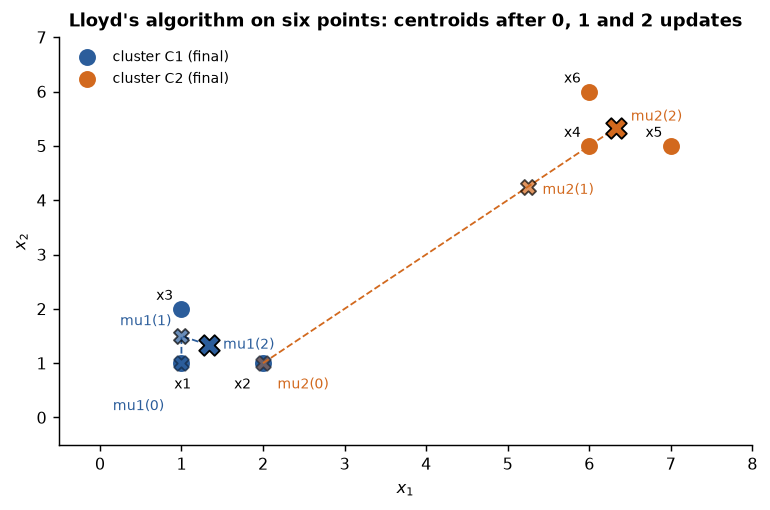

In [4]:
# scikit-learn's KMeans from the same initial centroids, and the trajectory of the centroids.
from sklearn.cluster import KMeans
km_hand = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1, random_state=0).fit(P)
print("sklearn centroids:", km_hand.cluster_centers_.round(4).tolist(), "| labels:", km_hand.labels_,
      "| inertia (J*):", round(km_hand.inertia_, 4), "| iterations:", km_hand.n_iter_)

# Centroid positions after each update, for the picture.
path = [P[[0, 1]].astype(float)]
for _ in range(2):
    d2 = ((P[:, None, :] - path[-1][None]) ** 2).sum(2); lab = d2.argmin(1)
    path.append(np.array([P[lab == j].mean(0) for j in range(2)]))
path = np.array(path)

fig, ax = plt.subplots(figsize=(6, 4))
for j, col in enumerate([BLUE, ORANGE]):
    ax.scatter(*P[labels_hand == j].T, s=70, color=col, label=f"cluster C{j+1} (final)")
    ax.plot(path[:, j, 0], path[:, j, 1], "--", color=col, lw=1)
    for t, (cx, cy) in enumerate(path[:, j]):
        ax.scatter(cx, cy, marker="X", s=130 if t == 2 else 70, color=col, edgecolor="k", alpha=0.4 + 0.3 * t, zorder=4)
offsets = {(0, 0): (-38, -26), (0, 1): (-34, 6), (0, 2): (8, -2), (1, 0): (8, -14), (1, 1): (8, -4), (1, 2): (8, 4)}   # label positions
for j in range(2):
    for t, (cx, cy) in enumerate(path[:, j]):
        ax.annotate(f"mu{j+1}({t})", (cx, cy), textcoords="offset points", xytext=offsets[(j, t)], fontsize=7.5, color=[BLUE, ORANGE][j])
for i, (px, py) in enumerate(P):
    ax.annotate(f"x{i+1}", (px, py), textcoords="offset points", xytext={0: (-4, -14), 1: (-16, -14)}.get(i, (-14, 5)), fontsize=8)
ax.set_xlim(-0.5, 8); ax.set_ylim(-0.5, 7); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Lloyd's algorithm on six points: centroids after 0, 1 and 2 updates")
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> The six points coloured by their final cluster, and the two centroids (crosses, darker as the iterations advance) moving from the poor start $\boldsymbol{\mu}_1^{(0)} = (1,1)$, $\boldsymbol{\mu}_2^{(0)} = (2,1)$ to the final positions $(1.33, 1.33)$ and $(6.33, 5.33)$. The orange centroid travels far: after the first assignment it is pulled to the middle of the plane by the three distant points, and only the second iteration delivers it to the right group. scikit-learn reports the same centroids, the same inertia $8/3$ and the same count of iterations as the numpy implementation.</p>

<div class="exercise"><h4>Exercise 1</h4><p>Start Lloyd's algorithm from $\boldsymbol{\mu}_1^{(0)} = (1, 1)$ and $\boldsymbol{\mu}_2^{(0)} = (6, 6)$ (change <code>P[[0, 1]]</code> to <code>P[[0, 5]]</code>). How many iterations are needed now, and does the final objective change? Then start from $\boldsymbol{\mu}_1^{(0)} = (1, 2)$ and $\boldsymbol{\mu}_2^{(0)} = (7, 5)$. Convince yourself, before running, that every sensible start reaches the same partition on these data — and then read Section 2.5, where that stops being true.</p></div>

### 2.5 Local minima and initialisation

Lloyd's algorithm descends to the nearest local minimum of $J$, and $J$ has many. The classic bad outcome is two centroids sharing one true group while another true group is split or absorbed by a neighbour; the algorithm cannot escape, because moving a centroid across the gap between groups would first <em>increase</em> $J$. The standard remedies are (i) a better start, k-means++, and (ii) <em>restarts</em>: run the algorithm from several initialisations and keep the solution with the smallest $J$ — scikit-learn's <code>n_init</code> parameter. The cell below generates five well-separated Gaussian groups, runs k-means ten times from plain random starts and ten times from k-means++ starts, and tabulates the inertia of each run.

seed                 0       1       2       3       4       5       6       7       8       9
random init     4861.6  4896.2  1388.1  1388.1  1388.1  1388.1  5198.8  5198.8  1388.1  1388.1
k-means++ init  1388.1  1388.1  1388.1  1388.1  1388.1  1388.1  1388.1  1388.1  1388.1  1388.1

best inertia found = 1388.1;  runs stuck in a worse local minimum: random 4/10, k-means++ 0/10


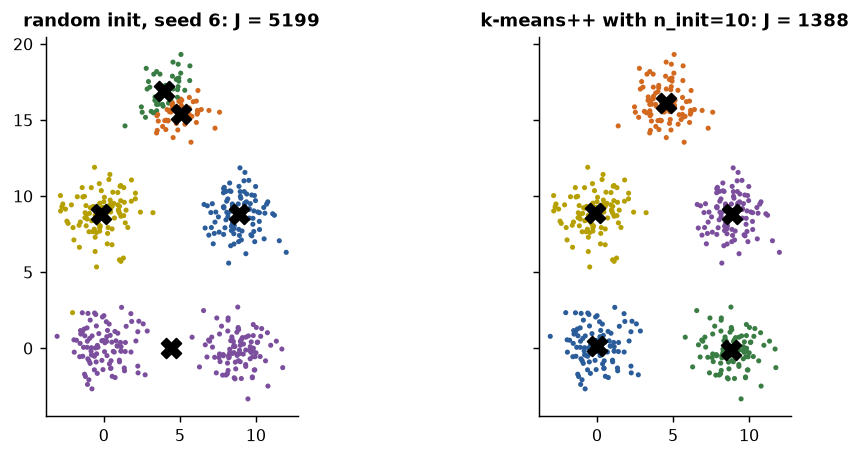

In [5]:
# Ten single runs from random starts versus ten from k-means++ starts on five well-separated groups.
from sklearn.datasets import make_blobs
centres5 = np.array([[0, 0], [9, 0], [0, 9], [9, 9], [4.5, 16]])
X_blobs, y_blobs = make_blobs(n_samples=500, centers=centres5, cluster_std=1.2, random_state=0)

runs = pd.DataFrame({
    "random init":    [KMeans(5, init="random",    n_init=1, random_state=s).fit(X_blobs).inertia_ for s in range(10)],
    "k-means++ init": [KMeans(5, init="k-means++", n_init=1, random_state=s).fit(X_blobs).inertia_ for s in range(10)],
}, index=pd.RangeIndex(10, name="seed")).round(1)
best = runs.min().min()
print(runs.T.to_string())
print(f"\nbest inertia found = {best:.1f};  runs stuck in a worse local minimum: random {int((runs['random init'] > best + 1).sum())}/10,"
      f" k-means++ {int((runs['k-means++ init'] > best + 1).sum())}/10")

worst_seed = int(runs["random init"].idxmax())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True, sharey=True)
for ax, (title, km) in zip(axes, [(f"random init, seed {worst_seed}: J = {runs.loc[worst_seed, 'random init']:.0f}",
                                    KMeans(5, init="random", n_init=1, random_state=worst_seed).fit(X_blobs)),
                                   (f"k-means++ with n_init=10: J = {best:.0f}", KMeans(5, n_init=10, random_state=0).fit(X_blobs))]):
    ax.scatter(*X_blobs.T, c=[PALETTE[l] for l in km.labels_], s=8, edgecolor="none")
    ax.scatter(*km.cluster_centers_.T, marker="X", s=120, color="k", zorder=4)
    ax.set_title(title); ax.set_aspect("equal")
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Left: the worst of the ten random-start runs. Two centroids share one group and a single centroid sits between two others — a local minimum from which Lloyd's algorithm cannot escape, with an inertia several times the best found. Right: the solution kept by scikit-learn's default procedure (k-means++ seeding, best of ten restarts), which recovers the five groups.</p>

The table shows the spread. From random starts, several of the ten runs end at an inertia far above the best; from k-means++ starts, all ten runs reach the same best value on these data. k-means++ does not guarantee the global minimum — on harder data a few runs still fail, which is why scikit-learn combines it with <code>n_init</code> restarts — but it converts a frequent failure into a rare one at negligible cost, and there is no situation in which plain random initialisation should be preferred.

<div class="box warn"><h4>Common misconception</h4><p>"k-means found the clusters" is a statement about one run from one start. The same data and the same $k$ can produce different partitions from different starts, and the printed inertia is the only internal evidence of which is better. Always run several initialisations (<code>n_init</code>), always report the inertia, and never interpret a partition that another start improves upon.</p></div>

### 2.6 Choosing k

The number of clusters is an input, not an output, and no internal criterion can determine it with certainty — the data do not know how many groups the analyst wants. Three heuristics are in common use; the first two are computed below, the third is described and then also computed.

**The elbow method.** Plot the inertia $J^\ast(k)$ against $k$. It always decreases (with $k = n$ it is zero), but if the data have $k_0$ groups it drops steeply up to $k_0$ and slowly thereafter; the "elbow" is the value where the gain per added cluster collapses. The method is visual, often ambiguous, and should be read as a range rather than a value.

**The silhouette.** For each point $i$, let $a(i)$ be its mean distance to the other members of its own cluster and $b(i)$ the smallest mean distance to the members of any other cluster. The silhouette of the point is

<div class="eq">$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}} \in [-1, 1]$$
<span class="where">which is near 1 when the point is much closer to its own cluster than to the nearest other one, near 0 when it lies between two clusters, and negative when it is probably in the wrong cluster. The mean silhouette over all points is a score for the whole partition; the $k$ that maximises it is chosen.</span></div>

Rousseeuw introduced the silhouette in 1987 as a graphical aid — the silhouette plot, in which the $s(i)$ are drawn sorted within each cluster — and the mean silhouette has become the most used internal index.<sup class="c"><a href="#r10">[10]</a></sup> Its cost is $O(n^2)$ because it needs all pairwise distances; for large $n$, scikit-learn's <code>sample_size</code> argument computes it on a subsample.

**The gap statistic.** Tibshirani, Walther and Hastie proposed to compare the observed $\log J^\ast(k)$ with its expectation under a <em>null</em> reference distribution with no cluster structure — uniform data over the bounding box of the sample — estimated from $B$ simulated datasets:<sup class="c"><a href="#r11">[11]</a></sup>

<div class="eq">$$\mathrm{Gap}(k) = \mathbb{E}^\ast\!\left[\log J^\ast_{\text{null}}(k)\right] - \log J^\ast(k)$$
<span class="where">The chosen $k$ is the smallest such that $\mathrm{Gap}(k) \ge \mathrm{Gap}(k+1) - s_{k+1}$, where $s_{k+1}$ is the standard error of the null estimate. Unlike the elbow and the silhouette, the gap statistic can return $k = 1$ — that is, it can say "there are no clusters" — which is often the correct answer.</span></div>

k                   1          2         3         4         5         6         7         8        9
inertia     28083.000  12877.000  8634.000  5004.000  1388.000  1269.000  1165.000  1071.000  974.000
silhouette        NaN      0.496     0.494     0.584     0.734     0.655     0.573     0.490    0.418
gap             0.088      0.130     0.208     0.414     1.430     1.317     1.241     1.175    1.114
gap s.e.        0.036      0.026     0.021     0.024     0.031     0.055     0.038     0.035    0.030

silhouette chooses k = 5;  gap statistic chooses k = 5;  true number of groups = 5


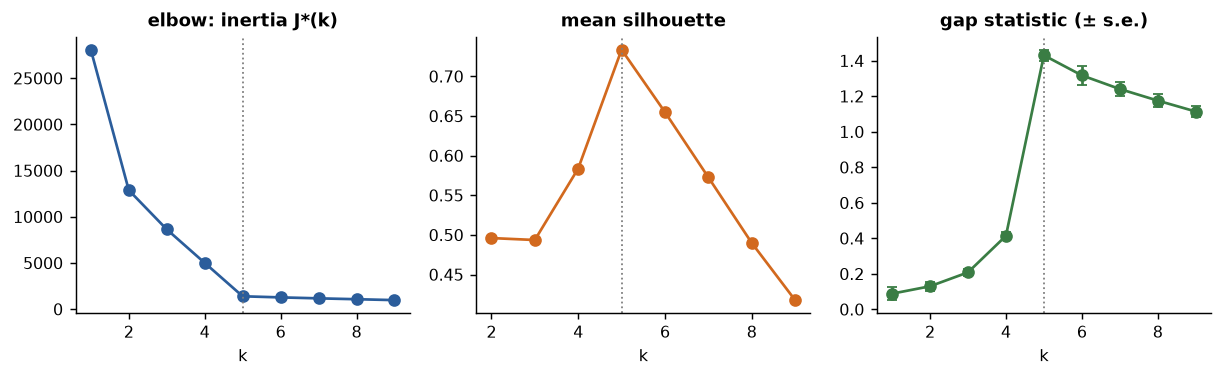

In [6]:
# Elbow, silhouette and gap statistic for k = 1..9 on the five-group data.
from sklearn.metrics import silhouette_score
ks = range(1, 10)
inertia = [KMeans(k, n_init=5, random_state=0).fit(X_blobs).inertia_ for k in ks]
sil = [np.nan] + [silhouette_score(X_blobs, KMeans(k, n_init=5, random_state=0).fit(X_blobs).labels_) for k in list(ks)[1:]]

def gap_statistic(X, ks, B=10, seed=0):
    '''Gap(k) and its standard error from B uniform reference datasets over the bounding box of X.'''
    rng = np.random.default_rng(seed); lo, hi = X.min(0), X.max(0); gaps, errs = [], []
    for k in ks:
        logW = np.log(KMeans(k, n_init=3, random_state=0).fit(X).inertia_)
        logW_null = np.log([KMeans(k, n_init=3, random_state=0).fit(rng.uniform(lo, hi, X.shape)).inertia_ for _ in range(B)])
        gaps.append(logW_null.mean() - logW); errs.append(logW_null.std() * np.sqrt(1 + 1 / B))
    return np.array(gaps), np.array(errs)
gaps, errs = gap_statistic(X_blobs, ks)
k_gap = next(k for k, g, g1, s1 in zip(ks, gaps, gaps[1:], errs[1:]) if g >= g1 - s1)

summary_k = pd.DataFrame({"inertia": np.round(inertia, 0), "silhouette": np.round(sil, 3), "gap": gaps.round(3), "gap s.e.": errs.round(3)}, index=pd.Index(ks, name="k"))
print(summary_k.T.to_string())
print(f"\nsilhouette chooses k = {int(np.nanargmax(sil)) + 1};  gap statistic chooses k = {k_gap};  true number of groups = 5")

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3))
axes[0].plot(ks, inertia, "o-", color=BLUE); axes[0].set_title("elbow: inertia J*(k)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks)[1:], sil[1:], "o-", color=ORANGE); axes[1].set_title("mean silhouette"); axes[1].set_xlabel("k")
axes[2].errorbar(ks, gaps, yerr=errs, fmt="o-", color=GREEN, capsize=3); axes[2].set_title("gap statistic (± s.e.)"); axes[2].set_xlabel("k")
for ax in axes: ax.axvline(5, color=GREY, ls=":", lw=1)
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> Three criteria for the number of clusters on data generated with five groups (dotted line). The inertia curve has its elbow at $k = 5$ — the decrease from 4 to 5 is large, from 5 to 6 small. The mean silhouette peaks at $k = 5$. The gap statistic jumps at $k = 5$ and its decision rule selects 5. The three agree here because the groups are well separated and round; on real data they frequently disagree, and the analyst reports the disagreement rather than the criterion that gave the desired answer.</p>

<div class="exercise"><h4>Exercise 2</h4><p>Regenerate <code>X_blobs</code> with <code>cluster_std=3.0</code> so that the five groups overlap, and re-run the cell. Which criterion degrades first? Then generate data with <em>no</em> groups — <code>X_blobs = np.random.default_rng(0).uniform(0, 10, (500, 2))</code> — and observe that the elbow and the silhouette still propose a $k$, while the gap statistic returns 1.</p></div>

### 2.7 Failure modes, demonstrated

Section 2.1 noted that the objective prefers round clusters of similar size and spread. The cell below constructs three datasets that violate one preference each and shows what k-means does with them.

(c) after standardising both features: ARI = 1.00


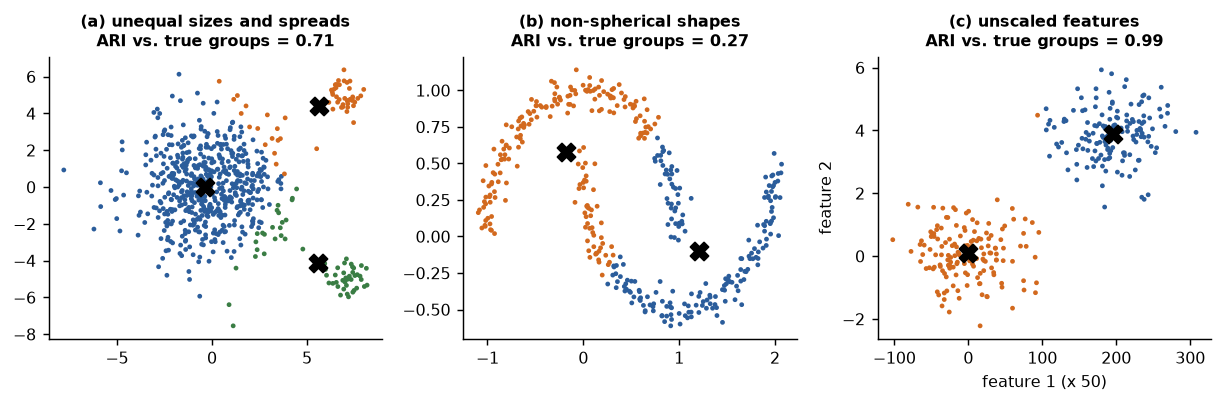

In [7]:
# Three situations in which k-means fails: unequal cluster sizes, non-spherical shapes, unscaled features.
from sklearn.datasets import make_moons
rng = np.random.default_rng(0)
# (a) unequal sizes: one large diffuse group and two small tight ones
Xa = np.vstack([rng.normal([0, 0], 2.0, (600, 2)), rng.normal([7, 5], 0.5, (40, 2)), rng.normal([7, -5], 0.5, (40, 2))])
ya = np.repeat([0, 1, 2], [600, 40, 40])
# (b) non-spherical: two interleaved half-moons
Xb_moons, yb_moons = make_moons(n_samples=400, noise=0.06, random_state=0)
# (c) unscaled: two round groups, but one feature measured in units 50 times larger
Xc_base, yc = make_blobs(n_samples=300, centers=[[0, 0], [4, 4]], cluster_std=0.8, random_state=0)
Xc = Xc_base * np.array([50, 1])          # feature 1 in 'µm²', feature 2 in 'ratio units'

from sklearn.metrics import adjusted_rand_score
fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.2))
for ax, (title, Xd, yd, k) in zip(axes, [("(a) unequal sizes and spreads", Xa, ya, 3), ("(b) non-spherical shapes", Xb_moons, yb_moons, 2), ("(c) unscaled features", Xc, yc, 2)]):
    km = KMeans(k, n_init=10, random_state=0).fit(Xd)
    ax.scatter(*Xd.T, c=[PALETTE[l] for l in km.labels_], s=7, edgecolor="none")
    ax.scatter(*km.cluster_centers_.T, marker="X", s=100, color="k", zorder=4)
    ax.set_title(f"{title}\nARI vs. true groups = {adjusted_rand_score(yd, km.labels_):.2f}", fontsize=9)
axes[2].set_xlabel("feature 1 (x 50)"); axes[2].set_ylabel("feature 2")
km_scaled = KMeans(2, n_init=10, random_state=0).fit(StandardScaler().fit_transform(Xc))
print(f"(c) after standardising both features: ARI = {adjusted_rand_score(yc, km_scaled.labels_):.2f}")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Three failures. (a) One large, diffuse group and two small, tight ones: k-means with $k = 3$ places a centroid on each small group but assigns to it a wide fringe of the large group as well, because the boundary between two centroids is the perpendicular bisector of the segment joining them, which falls far inside the diffuse group; the ARI of 0.71 counts those misassigned points. (b) Two half-moons: k-means can only draw straight boundaries between centroids, so it cuts each moon in half. (c) Two round, well-separated groups, but feature 1 is measured in units fifty times larger than feature 2: the Euclidean distance is dominated by feature 1 and the split is made along it alone, ignoring the vertical separation; standardising both features restores the correct partition, as the printed ARI shows. The adjusted Rand index (ARI) used in the titles is defined in Section 2.8.</p>

Each failure has a remedy elsewhere in the unit: unequal spreads are handled by Gaussian mixtures, which fit a covariance per cluster (Section 6); non-convex shapes by single-linkage hierarchical clustering, DBSCAN or spectral clustering (Sections 3 and 6); unscaled features by standardisation, which is the reason Section 1.3 standardised the breast-cancer data before anything else.

### 2.8 k-Means versus the hidden labels on the breast-cancer data

The running example is finally clustered. k-means with $k = 2$ is run on the 30 standardised features, and the partition is compared with the biopsy result that the algorithm never saw. The comparison uses a <strong>contingency table</strong> — cluster against label — and the <strong>adjusted Rand index</strong> (ARI) of Hubert and Arabie,<sup class="c"><a href="#r12">[12]</a></sup> which counts pairs of cases that the two partitions agree to put together or apart, corrected so that a random partition scores 0 and a perfect match scores 1. The ARI is invariant to the names of the clusters, which is essential: k-means calls its groups 0 and 1 in an arbitrary order that has nothing to do with "malignant" and "benign".

In [8]:
# k = 2 on the 30 standardised features; the hidden biopsy label is used only now, to assess the result.
km2 = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_std)
cont = pd.crosstab(pd.Series(km2.labels_, name="k-means cluster"), pd.Series(np.where(y_hidden == 0, "malignant", "benign"), name="biopsy"))
print(cont.to_string())
print(f"\nadjusted Rand index = {adjusted_rand_score(y_hidden, km2.labels_):.3f}")
# the best relabelling of the two clusters as diagnoses, for comparison with the classifiers of earlier units
agree = max((km2.labels_ == y_hidden).mean(), (km2.labels_ != y_hidden).mean())
print(f"agreement with the biopsy under the best relabelling = {agree:.1%}  (NOT an accuracy: no label was used to fit)")
km2_raw = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_raw)
print(f"the same with the UNstandardised features: ARI = {adjusted_rand_score(y_hidden, km2_raw.labels_):.3f}, "
      f"cluster sizes = {np.bincount(km2_raw.labels_).tolist()}")

biopsy           benign  malignant
k-means cluster                   
0                   339         36
1                    18        176

adjusted Rand index = 0.654
agreement with the biopsy under the best relabelling = 90.5%  (NOT an accuracy: no label was used to fit)
the same with the UNstandardised features: ARI = 0.491, cluster sizes = [438, 131]


On the standardised features, one k-means cluster contains the great majority of the benign cases and the other the great majority of the malignant ones; the adjusted Rand index is about 0.65 and, relabelling the clusters as diagnoses after the fact, about nine cases in ten fall on the "right" side. On the unstandardised features the ARI drops to about 0.49 and the partition becomes very unbalanced — one cluster of fewer than 150 cases — because <em>worst area</em> and <em>mean area</em>, with values in the hundreds and thousands, alone decide the distances; the algorithm has clustered tumour size, not tumour type.

<div class="box warn"><h4>The correction from Unit 2, restated</h4><p>The 90 % agreement is not an accuracy and k-means is not a classifier. A classifier learns a mapping from features to <em>the label</em>; k-means learned a partition of the feature space that minimises within-cluster scatter and happens — because nuclear size and shape are the dominant source of variation in these data, and also the basis of the diagnosis — to align with the label. Three consequences follow. (i) The alignment cannot be known without labels, so in a genuinely unlabelled study it cannot be claimed. (ii) The partition will not improve with more cases, because no information about the label enters it. (iii) A supervised classifier on the same data reaches 95–97 % (Unit 3, Unit 4) because it is optimising the right thing. The correct use of this result is the one in Section 8: when the labels do <em>not</em> exist, clustering is how one discovers that the cases fall into groups worth naming.</p></div>

<div class="exercise"><h4>Exercise 3</h4><p>Run k-means with $k = 3$ and $k = 4$ on <code>X_std</code> and print the contingency table against the biopsy. Do the extra clusters split the malignant cases, the benign cases, or both? Then compute the silhouette for $k = 2, \dots, 6$ on <code>X_std</code>. Which $k$ does it prefer, and what does that say about the "two groups" that the biopsy defines?</p></div>

## 3. Hierarchical clustering

### 3.1 The agglomerative algorithm

k-means needs $k$ in advance and returns one partition. Hierarchical clustering returns <em>all</em> partitions at once, nested inside each other, as a tree — the <strong>dendrogram</strong> — and $k$ is chosen afterwards by cutting the tree at a height. The <strong>agglomerative</strong> (bottom-up) algorithm is:

<ol>
<li>Start with $n$ clusters, one per point, and the $n \times n$ matrix of pairwise distances.</li>
<li>Find the two clusters at the smallest distance and <strong>merge</strong> them. Record the merge and its distance (the <em>height</em> of the merge).</li>
<li>Update the distance matrix: compute the distance between the new cluster and every remaining cluster using a <strong>linkage</strong> rule.</li>
<li>Repeat steps 2–3 until one cluster remains. The $n - 1$ recorded merges are the dendrogram.</li>
</ol>

Everything that distinguishes one hierarchical method from another is in step 3 — the definition of the distance between two <em>clusters</em>, given the distances between their <em>points</em>. The naive implementation costs $O(n^3)$ in time and $O(n^2)$ in memory for the distance matrix, which limits the method to some tens of thousands of cases; for larger $n$ one clusters a sample or the centroids of a preliminary k-means.

### 3.2 Distances between clusters: the linkage rules

For clusters $A$ and $B$ with $|A|$ and $|B|$ points and pairwise point distances $d(\mathbf{a}, \mathbf{b})$:

| Linkage | $D(A, B)$ | Character |
|---|---|---|
| **Single** (nearest neighbour) | $\min_{\mathbf{a} \in A,\, \mathbf{b} \in B} d(\mathbf{a}, \mathbf{b})$ | Merges clusters that touch anywhere; follows elongated or irregular shapes; prone to <em>chaining</em> (Section 3.5) |
| **Complete** (furthest neighbour) | $\max_{\mathbf{a} \in A,\, \mathbf{b} \in B} d(\mathbf{a}, \mathbf{b})$ | Merges only clusters whose furthest points are close; produces compact, round clusters of similar diameter; sensitive to outliers |
| **Average** (UPGMA) | $\dfrac{1}{|A|\,|B|} \displaystyle\sum_{\mathbf{a} \in A} \sum_{\mathbf{b} \in B} d(\mathbf{a}, \mathbf{b})$ | A compromise between the two; the method of the phylogenetic trees of BGM324 and of the gene-expression heatmaps of Section 3.6 |
| **Ward** (minimum variance) | $\sqrt{\dfrac{2\,|A|\,|B|}{|A| + |B|}}\; \lVert \bar{\mathbf{a}} - \bar{\mathbf{b}} \rVert_2$ | Merges the pair whose union increases the within-cluster sum of squares least; the hierarchical counterpart of k-means, with the same preference for round clusters of similar size |

The Ward formula is written as scipy implements it: merging $A$ and $B$ increases the within-cluster sum of squares by $\frac{|A||B|}{|A|+|B|} \lVert \bar{\mathbf{a}} - \bar{\mathbf{b}} \rVert^2$ (with centroids $\bar{\mathbf{a}}, \bar{\mathbf{b}}$), and scipy reports the square root of twice that quantity so that for two single points it equals their Euclidean distance. Ward's 1963 paper defines the method as the merge that minimises the loss of an objective function, the error sum of squares being the case that became standard.<sup class="c"><a href="#r14">[14]</a></sup> All four rules are special cases of the Lance–Williams recurrence,<sup class="c"><a href="#r13">[13]</a></sup> which expresses the distance between a merged cluster $A \cup B$ and any other cluster $C$ as a linear combination of $D(A, C)$, $D(B, C)$ and $D(A, B)$, so the distance matrix can be updated without returning to the points.

### 3.3 Worked example by hand: the first three merges

Twenty aspirates are drawn at random from the breast-cancer data and described by two features, mean radius and mean texture, rounded to one decimal so that distances can be checked on paper. The cell prints the twenty points and the six smallest pairwise distances. The hand trace follows.

In [9]:
# A 20-case subset in two features (rounded to one decimal for hand calculation) and its closest pairs.
from scipy.spatial.distance import pdist, squareform
rng = np.random.default_rng(0)
sub_idx = rng.choice(len(X_df), 20, replace=False)
sub = X_df.iloc[sub_idx][["mean radius", "mean texture"]].round(1).to_numpy()
sub_label = np.where(y_hidden[sub_idx] == 0, "M", "B")
print("the 20 cases (number: radius, texture, hidden label):")
print("   ".join(f"{i}: ({r}, {t}) {l}" for i, ((r, t), l) in enumerate(zip(sub, sub_label))))

D = squareform(pdist(sub))                                # 20 x 20 Euclidean distance matrix
iu, ju = np.triu_indices(20, k=1)
closest = pd.DataFrame({"case i": iu, "case j": ju, "distance": D[iu, ju]}).sort_values("distance").head(6)
closest["d² by hand"] = [f"({sub[i,0]}-{sub[j,0]})² + ({sub[i,1]}-{sub[j,1]})² = {((sub[i]-sub[j])**2).sum():.2f}" for i, j in zip(closest["case i"], closest["case j"])]
print("\nsix smallest pairwise distances:"); print(closest.round(3).to_string(index=False))

the 20 cases (number: radius, texture, hidden label):
0: (13.4, 20.5) M   1: (12.3, 12.4) B   2: (13.7, 17.9) B   3: (13.7, 16.3) B   4: (19.4, 18.2) M   5: (9.6, 16.8) B   6: (9.0, 18.9) B   7: (10.3, 16.6) B   8: (11.7, 17.1) B   9: (16.5, 18.3) B   10: (9.8, 19.9) B   11: (12.6, 17.2) B   12: (13.9, 16.2) B   13: (12.5, 24.0) M   14: (13.5, 12.7) B   15: (11.0, 21.4) M   16: (9.7, 18.1) B   17: (16.2, 18.8) M   18: (9.4, 21.7) B   19: (15.3, 14.3) M

six smallest pairwise distances:
 case i  case j  distance                         d² by hand
      3      12     0.224 (13.7-13.9)² + (16.3-16.2)² = 0.05
      9      17     0.583 (16.5-16.2)² + (18.3-18.8)² = 0.34
      5       7     0.728  (9.6-10.3)² + (16.8-16.6)² = 0.53
      8      11     0.906 (11.7-12.6)² + (17.1-17.2)² = 0.82
      6      16     1.063   (9.0-9.7)² + (18.9-18.1)² = 1.13
      1      14     1.237 (12.3-13.5)² + (12.4-12.7)² = 1.53


**Merge 1.** The smallest entry of the distance matrix is between cases 3 = (13.7, 16.3) and 12 = (13.9, 16.2): $d = \sqrt{0.2^2 + 0.1^2} = \sqrt{0.05} \approx 0.224$. They form cluster $\{3, 12\}$ at height 0.224.

**Merge 2.** The matrix is updated with the chosen linkage rule. The next smallest distance among the remaining entries is between cases 9 = (16.5, 18.3) and 17 = (16.2, 18.8): $d = \sqrt{0.3^2 + 0.5^2} = \sqrt{0.34} \approx 0.583$. Could the new cluster $\{3, 12\}$ be closer to some case than 0.583? No: under any of the four rules the distance from $\{3, 12\}$ to a case $c$ is at least $\min\{d(3, c), d(12, c)\}$, and every such distance exceeds 0.583 (the table shows that no pair involving 3 or 12 other than themselves is among the six closest). So the second merge is $\{9, 17\}$ at height 0.583, for every linkage.

**Merge 3.** By the same reasoning, cases 5 = (9.6, 16.8) and 7 = (10.3, 16.6): $d = \sqrt{0.7^2 + 0.2^2} = \sqrt{0.53} \approx 0.728$. Third merge $\{5, 7\}$ at 0.728.

**Where the linkages diverge.** The rules agree on the first merges only because those pairs are isolated. Consider the updated distance between cluster $\{3, 12\}$ and case 2 = (13.7, 17.9): $d(3, 2) = \sqrt{0^2 + 1.6^2} = 1.600$ and $d(12, 2) = \sqrt{0.2^2 + 1.7^2} = \sqrt{2.93} \approx 1.712$. Single linkage records $\min = 1.600$, complete linkage $\max = 1.712$, average linkage $(1.600 + 1.712)/2 = 1.656$, and Ward, with the centroid of $\{3, 12\}$ at $(13.8, 16.25)$, records $\sqrt{\tfrac{2 \cdot 2 \cdot 1}{3}} \cdot \sqrt{0.1^2 + 1.65^2} \approx 1.155 \times 1.653 \approx 1.909$. As merges accumulate, these differences compound and the four dendrograms become different trees. The cell confirms the three merges and the four updated distances.

first three merges (identical for every linkage):
 cluster a  cluster b  height  size
         3         12   0.224     2
         9         17   0.583     2
         5          7   0.728     2

D({3,12}, 2): single = 1.600, complete = 1.712, average = 1.656, ward = 1.909


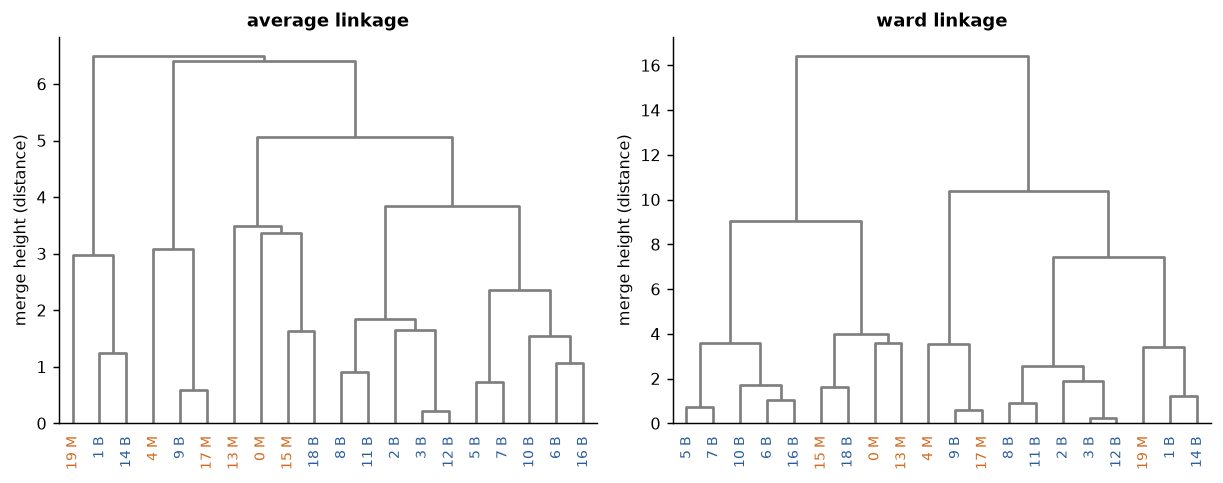

In [10]:
# scipy's linkage matrix: row r = [cluster a, cluster b, height, size]; clusters >= 20 are merged clusters (20 = first merge).
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
Z = {m: linkage(sub, method=m) for m in ["single", "complete", "average", "ward"]}
print("first three merges (identical for every linkage):")
print(pd.DataFrame(Z["average"][:3], columns=["cluster a", "cluster b", "height", "size"]).astype({"cluster a": int, "cluster b": int, "size": int}).round(3).to_string(index=False))

# Updated distance between the cluster {3, 12} and case 2 under each rule, computed from the points.
A, c = sub[[3, 12]], sub[2]
d_pts = np.linalg.norm(A - c, axis=1)
ward = np.sqrt(2 * 2 * 1 / 3) * np.linalg.norm(A.mean(0) - c)
print(f"\nD({{3,12}}, 2): single = {d_pts.min():.3f}, complete = {d_pts.max():.3f}, average = {d_pts.mean():.3f}, ward = {ward:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, m in zip(axes, ["average", "ward"]):
    dendrogram(Z[m], ax=ax, labels=[f"{i} {l}" for i, l in enumerate(sub_label)], leaf_font_size=8, leaf_rotation=90, color_threshold=0, above_threshold_color=GREY)
    ax.set_title(f"{m} linkage"); ax.set_ylabel("merge height (distance)")
    for lab in ax.get_xticklabels(): lab.set_color(ORANGE if lab.get_text().endswith("M") else BLUE)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Dendrograms of the twenty cases under average linkage (left) and Ward linkage (right). Leaves are labelled with the case number and the hidden diagnosis (M in orange, B in blue). Reading from the bottom: the lowest three joins are the three merges traced by hand — $\{3, 12\}$ at 0.22, $\{9, 17\}$ at 0.58, $\{5, 7\}$ at 0.73 — and are the same in both trees; higher up, the trees differ in the order and height of the merges, and Ward's heights grow faster because its criterion penalises merging large clusters. Note that the top-level splits do <em>not</em> follow the hidden diagnosis: with only radius and texture, and only twenty cases, the malignant cases (orange) are scattered through both trees, and cutting either tree at $k = 2$ gives an ARI near zero against the diagnosis (next cell). This is a two-feature view of a thirty-feature problem, and a reminder that a dendrogram always has a top-level split whether or not it means anything.</p>

### 3.4 Cutting the tree and the cophenetic correlation

A dendrogram becomes a partition when it is cut horizontally: every branch that crosses the cut height is one cluster. Cutting so as to obtain exactly $k$ clusters (<code>fcluster(Z, k, "maxclust")</code>) or at a chosen distance (<code>criterion="distance"</code>) are the two usual choices. The "right" height is often read from the dendrogram as the longest vertical stretch with no merges — a large gap between successive merge heights means that the clusters below it are much more similar internally than to each other.

A dendrogram also implies a distance between any two points: the height at which they are first joined, called the <strong>cophenetic distance</strong>. The <strong>cophenetic correlation coefficient</strong> is the Pearson correlation between the cophenetic distances and the original distances over all pairs;<sup class="c"><a href="#r15">[15]</a></sup> it measures how faithfully the tree represents the distance matrix and is the standard way to compare linkage rules on the same data (values above about 0.75 are usually regarded as a faithful representation). The cell cuts each tree into two clusters, compares the cut with the hidden labels, and reports the cophenetic correlation of each linkage.

In [11]:
# Cut each of the four trees into k = 2 clusters, compare with the hidden diagnosis, and compute the cophenetic correlation.
rows = []
for m, Zm in Z.items():
    cut = fcluster(Zm, 2, criterion="maxclust")
    rows.append({"linkage": m, "cluster sizes": np.bincount(cut)[1:].tolist(), "ARI vs. diagnosis": adjusted_rand_score(sub_label, cut),
                 "cophenetic corr.": cophenet(Zm, pdist(sub))[0], "largest gap between merge heights": np.diff(Zm[:, 2]).max()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

 linkage cluster sizes  ARI vs. diagnosis  cophenetic corr.  largest gap between merge heights
  single       [19, 1]              0.130             0.640                              0.516
complete       [14, 6]              0.104             0.675                              2.434
 average       [3, 17]             -0.012             0.690                              1.353
    ward       [9, 11]             -0.037             0.618                              6.037


The table makes three points. First, the cophenetic correlation is highest for average linkage, as is typical: average linkage is, by construction, the rule that best preserves the original distances, which is why it is the default of phylogenetics and of the heatmaps of Section 3.6. Second, cutting the trees at $k = 2$ gives partitions of different balance and different agreement with the diagnosis — single linkage in particular tends to peel off one or two outlying cases and leave the rest together, the small-scale version of the chaining effect shown next. Third, the "largest gap" column is a crude automatic reading of the dendrogram; it is a heuristic, not a test.

### 3.5 The chaining effect of single linkage

Single linkage merges two clusters as soon as <em>any</em> pair of their points is close. A thin line of points between two groups — a few intermediate patients, a noisy transition, a bridge — is therefore enough to join the groups, link by link, before the groups themselves are complete. The resulting clusters are long chains rather than compact sets. The same property is a virtue when the clusters genuinely are elongated or curved (the half-moons of Figure 5b), so the effect is a trade-off, not a bug.

single   linkage on the half-moons (k = 2): ARI = 1.00
average  linkage on the half-moons (k = 2): ARI = 0.33
ward     linkage on the half-moons (k = 2): ARI = 0.24


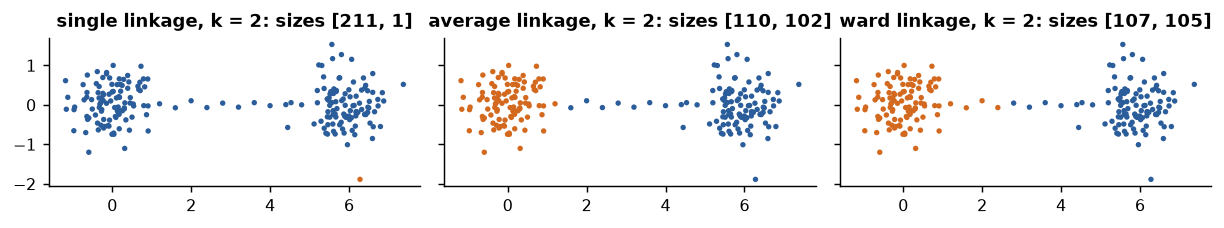

In [12]:
# Two compact groups joined by a sparse bridge of 12 points: single linkage chains through the bridge, Ward does not.
from sklearn.cluster import AgglomerativeClustering
rng = np.random.default_rng(0)
g1 = rng.normal([0, 0], 0.5, (100, 2)); g2 = rng.normal([6, 0], 0.5, (100, 2))
bridge = np.c_[np.linspace(0.8, 5.2, 12), rng.normal(0, 0.05, 12)]
X_chain = np.vstack([g1, g2, bridge])

fig, axes = plt.subplots(1, 3, figsize=(9.5, 2.9), sharex=True, sharey=True)
for ax, m in zip(axes, ["single", "average", "ward"]):
    lab = AgglomerativeClustering(n_clusters=2, linkage=m).fit_predict(X_chain)
    ax.scatter(*X_chain.T, c=[PALETTE[l] for l in lab], s=9, edgecolor="none")
    ax.set_title(f"{m} linkage, k = 2: sizes {np.bincount(lab).tolist()}"); ax.set_aspect("equal")
    # and the same data on the half-moons of Section 2.7
    print(f"{m:8s} linkage on the half-moons (k = 2): ARI = {adjusted_rand_score(yb_moons, AgglomerativeClustering(2, linkage=m).fit_predict(Xb_moons)):.2f}")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> Two hundred points in two tight groups, plus twelve points forming a bridge. Single linkage (left) follows the bridge and joins both groups into one cluster of 211 points, leaving a single outlier as the "second cluster". Average and Ward linkage (centre, right) cut the bridge and recover the two groups. The printout shows the other side of the trade-off: on the half-moons, single linkage is the only one of the three that recovers the two curved shapes, because chaining is exactly what following a curve requires.</p>

**Divisive methods.** The opposite strategy — start with one cluster containing everything and split recursively — is <strong>divisive</strong> hierarchical clustering. It is rarely used in its exact form because choosing the best split of a cluster is combinatorial (there are $2^{n-1} - 1$ ways to split $n$ points in two); the practical algorithm DIANA<sup class="c"><a href="#r7">[7]</a></sup> splits by moving the most dissimilar points out one at a time, and <em>bisecting k-means</em> (available as <code>sklearn.cluster.BisectingKMeans</code>) splits the largest or least compact cluster with $k = 2$ at each step. Divisive methods have the advantage of getting the top of the tree — the coarse structure — right first, whereas agglomerative methods, having committed to early merges, cannot undo them.

### 3.6 Application: gene-expression heatmaps

In 1998 Eisen, Spellman, Brown and Botstein applied average-linkage hierarchical clustering with a correlation-based distance to the expression of thousands of yeast genes across time courses, reordered the rows and columns of the expression matrix by the dendrograms, and displayed the result as a colour image — the "clustered heatmap" that has been the standard visualisation of expression data ever since.<sup class="c"><a href="#r16">[16]</a></sup> The idea is simple: genes with similar expression profiles end up adjacent, so blocks of colour appear where groups of genes behave alike in groups of conditions, and both the gene clusters and the sample clusters can be read off the margins. The cell below builds a miniature on the wine data<sup class="c"><a href="#r17">[17]</a></sup> — 178 samples × 13 chemical measurements, a stand-in for samples × genes that ships with scikit-learn — clustering both samples and features with average linkage on the correlation distance, exactly as Eisen did.

three sample clusters vs. the hidden cultivar: ARI = 0.82; cluster sizes [56, 58, 64]; cultivar sizes [59, 71, 48]


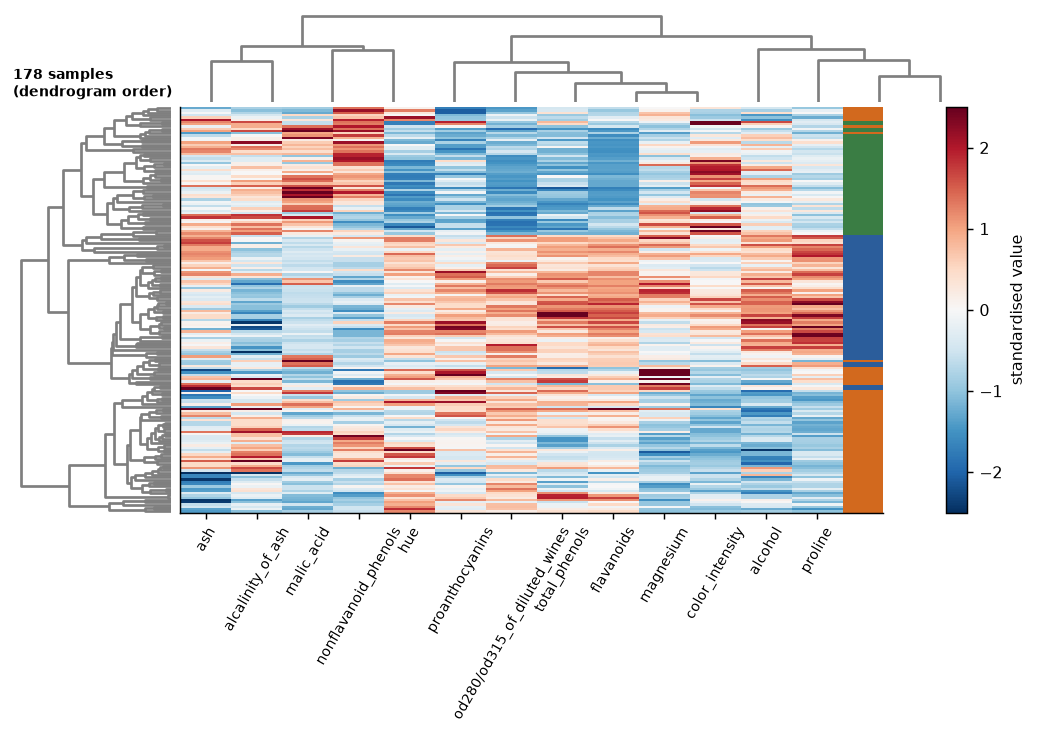

In [13]:
# An Eisen-style clustered heatmap: rows (samples) and columns (features) reordered by average-linkage dendrograms.
wine = datasets.load_wine(as_frame=True)
W = StandardScaler().fit_transform(wine.data)                     # 178 samples x 13 features, each feature standardised
Z_rows = linkage(W, method="average", metric="correlation")       # cluster samples by the correlation of their profiles
Z_cols = linkage(W.T, method="average", metric="correlation")     # cluster features by the correlation across samples
row_order = dendrogram(Z_rows, no_plot=True)["leaves"]; col_order = dendrogram(Z_cols, no_plot=True)["leaves"]

fig = plt.figure(figsize=(9.5, 5))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 5], height_ratios=[1, 4.5], wspace=0.02, hspace=0.02)
ax_col = fig.add_subplot(gs[0, 1]); dendrogram(Z_cols, ax=ax_col, no_labels=True, color_threshold=0, above_threshold_color=GREY); ax_col.axis("off")
ax_row = fig.add_subplot(gs[1, 0]); dendrogram(Z_rows, ax=ax_row, orientation="left", no_labels=True, color_threshold=0, above_threshold_color=GREY); ax_row.axis("off")
ax_hm = fig.add_subplot(gs[1, 1])
im = ax_hm.imshow(W[row_order][:, col_order], aspect="auto", cmap="RdBu_r", vmin=-2.5, vmax=2.5, interpolation="nearest")
ax_hm.set_xticks(range(13)); ax_hm.set_xticklabels(wine.feature_names[j] for j in col_order); ax_hm.tick_params(axis="x", rotation=60, labelsize=7.5)
ax_hm.set_yticks([]); ax_row.set_title("178 samples\n(dendrogram order)", fontsize=8, loc="left")
# the hidden cultivar of each sample, as a colour bar at the right edge
cult = np.asarray(wine.target)[row_order]
ax_hm.imshow(cult[:, None], extent=(12.5, 13.3, 177.5, -0.5), aspect="auto", cmap=plt.matplotlib.colors.ListedColormap([BLUE, ORANGE, GREEN]), interpolation="nearest"); ax_hm.set_xlim(-0.5, 13.3)
fig.colorbar(im, ax=ax_hm, fraction=0.03, pad=0.08, label="standardised value")
cut3 = fcluster(Z_rows, 3, criterion="maxclust")
print(f"three sample clusters vs. the hidden cultivar: ARI = {adjusted_rand_score(wine.target, cut3):.2f}; cluster sizes {np.bincount(cut3)[1:].tolist()}; cultivar sizes {np.bincount(wine.target).tolist()}")

<p class="caption"><b>Figure 8.</b> A clustered heatmap in the style of Eisen et al. Each row is a wine sample, each column a standardised chemical measurement (red above the mean, blue below); rows and columns have been reordered by the dendrograms drawn on the margins. Blocks of colour appear: a group of samples high in flavanoids, phenols and proanthocyanins, another high in colour intensity and alcohol, a third low in both. The narrow bar at the right shows the hidden cultivar of each sample (three colours) and reveals that the sample clusters largely coincide with the three cultivars, with an ARI printed above the figure. Note what the figure does <em>not</em> show: the raw matrix in its original order would be noise to the eye; the structure is produced by the reordering.</p>

<div class="box bridge"><h4>Bridge to bioinformatics</h4><p>The UPGMA tree of BGM324 Unit 1, built from a matrix of pairwise sequence distances, <em>is</em> average-linkage agglomerative clustering: the leaves are sequences, the merge heights are evolutionary distances, and the cophenetic distances are the branch lengths. The clustered heatmap is the same algorithm applied twice, to the rows and to the columns of an expression matrix, and Section 8 describes how it defined the molecular subtypes of breast cancer.</p></div>

## 4. Principal component analysis

### 4.1 Two views of the same idea

Principal component analysis (PCA) replaces $p$ correlated features by $q \le p$ new features — the <strong>principal components</strong> — that are linear combinations of the originals, uncorrelated with each other, and ordered by the amount of variance they carry. Two formulations lead to the same components.

**Variance maximisation.** Find the unit vector $\mathbf{w}_1$ such that the projection of the (centred) data onto it, $z_i = \mathbf{w}_1^\top \mathbf{x}_i$, has the largest possible variance; then find $\mathbf{w}_2 \perp \mathbf{w}_1$ with the largest remaining variance, and so on. This is Hotelling's 1933 formulation,<sup class="c"><a href="#r18">[18]</a></sup> and the one from which the method takes its name.

**Minimum reconstruction error.** Find the $q$-dimensional subspace (a line for $q = 1$, a plane for $q = 2$) such that the sum of squared perpendicular distances from the points to the subspace is smallest. This is Pearson's 1901 formulation — "lines and planes of closest fit to systems of points in space"<sup class="c"><a href="#r19">[19]</a></sup> — and it says that PCA is the best possible <em>linear compression</em> of the data: the $q$ coordinates of each point in that subspace are the summary from which the point can be reconstructed with the least total squared error.

The two agree because, for centred data, the squared distance from a point to the origin equals the squared length of its projection on the subspace plus the squared perpendicular distance to it; the first sum is fixed, so maximising the projected variance and minimising the residual are the same problem. Both lead to the covariance matrix.

### 4.2 Covariance, eigenvectors, eigenvalues — worked example by hand

Let $\mathbf{X}$ be the $n \times p$ data matrix with column means subtracted. Its <strong>sample covariance matrix</strong> is

<div class="eq">$$\mathbf{S} = \frac{1}{n-1}\,\mathbf{X}^\top \mathbf{X}, \qquad S_{jl} = \frac{1}{n-1}\sum_{i=1}^{n} x_{ij}\,x_{il}$$
<span class="where">a symmetric $p \times p$ matrix whose diagonal holds the variances of the features and whose off-diagonal entries hold their covariances. The variance of a projection $\mathbf{w}^\top \mathbf{x}$ is $\mathbf{w}^\top \mathbf{S}\, \mathbf{w}$, and maximising it subject to $\lVert \mathbf{w} \rVert = 1$ (by a Lagrange multiplier) gives $\mathbf{S}\mathbf{w} = \lambda \mathbf{w}$: the directions of maximal variance are the <strong>eigenvectors</strong> of $\mathbf{S}$, and the variance along each is its <strong>eigenvalue</strong> $\lambda$. Because $\mathbf{S}$ is symmetric, its eigenvectors are orthogonal and its eigenvalues real and non-negative. Sorted in decreasing order, $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_p$, the eigenvectors are the principal components, and $\lambda_j / \sum_l \lambda_l$ is the <strong>proportion of variance explained</strong> by component $j$.</span></div>

**Worked example.** Five points in two dimensions:

| point | $x_1$ | $x_2$ |
|---|---|---|
| 1 | 2 | 1 |
| 2 | 3 | 3 |
| 3 | 4 | 2 |
| 4 | 5 | 4 |
| 5 | 6 | 5 |

**Step 1 — centre.** Means: $\bar{x}_1 = (2+3+4+5+6)/5 = 4$, $\bar{x}_2 = (1+3+2+4+5)/5 = 3$. Centred data: $(-2, -2), (-1, 0), (0, -1), (1, 1), (2, 2)$.

**Step 2 — covariance matrix.** With $n - 1 = 4$:
$S_{11} = (4 + 1 + 0 + 1 + 4)/4 = 2.5$; $S_{22} = (4 + 0 + 1 + 1 + 4)/4 = 2.5$; $S_{12} = ((-2)(-2) + (-1)(0) + (0)(-1) + (1)(1) + (2)(2))/4 = 9/4 = 2.25$. So
$$\mathbf{S} = \begin{pmatrix} 2.5 & 2.25 \\ 2.25 & 2.5 \end{pmatrix}.$$

**Step 3 — eigenvalues.** Solve $\det(\mathbf{S} - \lambda \mathbf{I}) = (2.5 - \lambda)^2 - 2.25^2 = 0$, i.e. $2.5 - \lambda = \pm 2.25$: $\lambda_1 = 4.75$, $\lambda_2 = 0.25$. Total variance $\lambda_1 + \lambda_2 = 5 = S_{11} + S_{22}$ (the trace is preserved). Proportion explained by the first component: $4.75 / 5 = 0.95$.

**Step 4 — eigenvectors.** For $\lambda_1 = 4.75$: $(\mathbf{S} - 4.75\mathbf{I})\mathbf{w} = 0$ gives $-2.25 w_1 + 2.25 w_2 = 0$, so $w_1 = w_2$ and the unit eigenvector is $\mathbf{w}_1 = (1, 1)/\sqrt{2} \approx (0.707, 0.707)$. For $\lambda_2 = 0.25$: $2.25 w_1 + 2.25 w_2 = 0$, so $\mathbf{w}_2 = (1, -1)/\sqrt{2} \approx (0.707, -0.707)$. The two are orthogonal, as promised.

**Step 5 — project.** The score of each centred point on the first component is $z_{i1} = \mathbf{w}_1^\top \mathbf{x}_i = (x_{i1} + x_{i2})/\sqrt{2}$: $-4/\sqrt{2}, -1/\sqrt{2}, -1/\sqrt{2}, 2/\sqrt{2}, 4/\sqrt{2} \approx -2.83, -0.71, -0.71, 1.41, 2.83$. On the second, $z_{i2} = (x_{i1} - x_{i2})/\sqrt{2}$: $0, -0.71, 0.71, 0, 0$. The variance of the first scores is $(8 + 0.5 + 0.5 + 2 + 8)/4 = 4.75 = \lambda_1$ ✓, and the sum of squared second scores, $0.5 + 0.5 = 1.0 = 4 \lambda_2$, is the total squared reconstruction error if the data are compressed to one dimension. The cell confirms every number.

In [14]:
# PCA by hand in numpy: centre, covariance, eigen-decomposition, projection; then sklearn's PCA on the same five points.
from sklearn.decomposition import PCA
Q = np.array([[2, 1], [3, 3], [4, 2], [5, 4], [6, 5]], dtype=float)
Qc = Q - Q.mean(axis=0)                              # step 1: centre
S = Qc.T @ Qc / (len(Q) - 1)                         # step 2: covariance matrix
evals, evecs = np.linalg.eigh(S)                     # step 3-4: eigh returns ascending eigenvalues for symmetric matrices
order = np.argsort(evals)[::-1]; evals, evecs = evals[order], evecs[:, order]
scores = Qc @ evecs                                  # step 5: project
print("means:", Q.mean(0), "\ncovariance matrix:\n", S)
print("eigenvalues:", evals, "| proportion explained:", (evals / evals.sum()).round(3))
print("eigenvectors (columns):\n", evecs.round(4))
print("scores on PC1:", scores[:, 0].round(3), "| variance of PC1 scores:", scores[:, 0].var(ddof=1).round(3))
print("scores on PC2:", scores[:, 1].round(3), "| sum of squared PC2 scores (reconstruction error with 1 component):", (scores[:, 1] ** 2).sum().round(3))

pca_hand = PCA(n_components=2).fit(Q)
print("\nsklearn PCA: explained_variance_ =", pca_hand.explained_variance_, "| components_ (rows):\n", pca_hand.components_.round(4))
print("sklearn scores on PC1:", pca_hand.transform(Q)[:, 0].round(3))

means: [4. 3.] 
covariance matrix:
 [[2.5  2.25]
 [2.25 2.5 ]]
eigenvalues: [4.75 0.25] | proportion explained: [0.95 0.05]
eigenvectors (columns):
 [[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
scores on PC1: [-2.828 -0.707 -0.707  1.414  2.828] | variance of PC1 scores: 4.75
scores on PC2: [ 0.     0.707 -0.707  0.     0.   ] | sum of squared PC2 scores (reconstruction error with 1 component): 1.0

sklearn PCA: explained_variance_ = [4.75 0.25] | components_ (rows):
 [[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]
sklearn scores on PC1: [-2.828 -0.707 -0.707  1.414  2.828]


numpy and scikit-learn reproduce the hand calculation: eigenvalues 4.75 and 0.25, the proportions 0.95 and 0.05, eigenvectors $\pm(0.707, 0.707)$ and $\pm(0.707, -0.707)$, and the scores. The signs of the eigenvectors may differ between the hand solution, <code>eigh</code> and <code>PCA</code> — an eigenvector multiplied by $-1$ is still an eigenvector — so a component's sign carries no meaning and the scores along it may be flipped from one software to another. This is the first of the two ambiguities (the second belongs to ICA, Section 5.3). Note too that <code>PCA.components_</code> stores the eigenvectors as <em>rows</em>, whereas <code>eigh</code> returns them as <em>columns</em>.

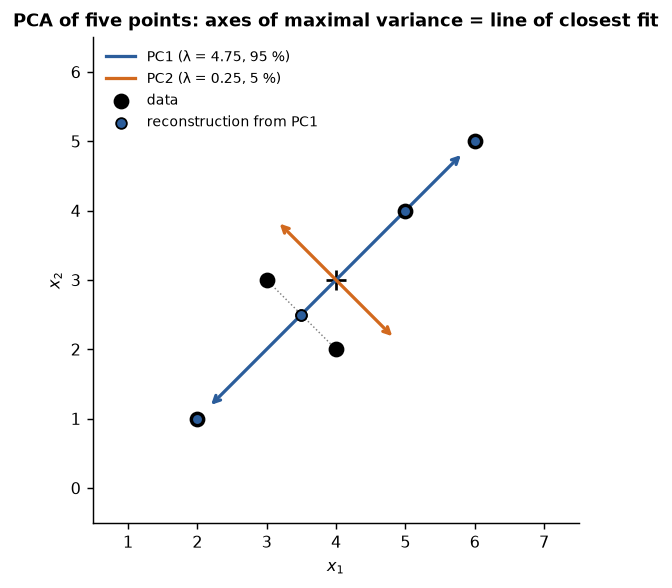

In [15]:
# The five points, the two principal axes through the mean, and the projection of each point onto PC1.
w1, w2 = evecs[:, 0], evecs[:, 1]
proj = Q.mean(0) + np.outer(scores[:, 0], w1)        # reconstruction from the first component only
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for s_, v, col, name in [(2.6, w1, BLUE, "PC1 (λ = 4.75, 95 %)"), (1.2, w2, ORANGE, "PC2 (λ = 0.25, 5 %)")]:
    ax.annotate("", xy=Q.mean(0) + s_ * v, xytext=Q.mean(0) - s_ * v, arrowprops=dict(arrowstyle="<->", color=col, lw=1.8))
    ax.plot([], [], color=col, lw=1.8, label=name)
for q, pr in zip(Q, proj):
    ax.plot([q[0], pr[0]], [q[1], pr[1]], color=GREY, lw=0.8, ls=":")
ax.scatter(*Q.T, s=60, color="k", zorder=4, label="data"); ax.scatter(*proj.T, s=35, color=BLUE, edgecolor="k", zorder=5, label="reconstruction from PC1")
ax.scatter(*Q.mean(0), marker="+", s=120, color="k")
ax.set_aspect("equal"); ax.set_xlim(0.5, 7.5); ax.set_ylim(-0.5, 6.5); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.set_title("PCA of five points: axes of maximal variance = line of closest fit")
fig.tight_layout()

<p class="caption"><b>Figure 9.</b> The five points (black), their mean (cross), the first principal axis (blue, along $(1,1)/\sqrt{2}$) and the second (orange, perpendicular). The dotted segments are the perpendicular distances from each point to the first axis; their squared lengths sum to 1.0, the reconstruction error of Step 5. The blue dots on the axis are the points as they would be reconstructed from a single number each, their PC1 score. Hotelling's view (maximal variance along the blue axis) and Pearson's view (minimal squared dotted distances) describe the same line.</p>

### 4.3 Explained variance and the scree plot: the breast-cancer features, with and without scaling

With 30 features the covariance matrix is $30 \times 30$ and has 30 eigenvalues. The <strong>scree plot</strong> draws them (or the proportions of variance) in decreasing order; the number of components to keep is read either from an elbow in the plot or from the cumulative proportion crossing a threshold such as 80 % or 95 %. The cell computes the eigenvalues for the raw features and for the standardised ones.

RAW features:          PC1 explains 98.2%, PC2 1.6%; PC1 is dominated by 'worst area' (loading 0.852)
STANDARDISED features: PC1 explains 44.3%, PC2 19.0%, PC3 9.4%; first two together 63.2%; 10 components reach 95 %


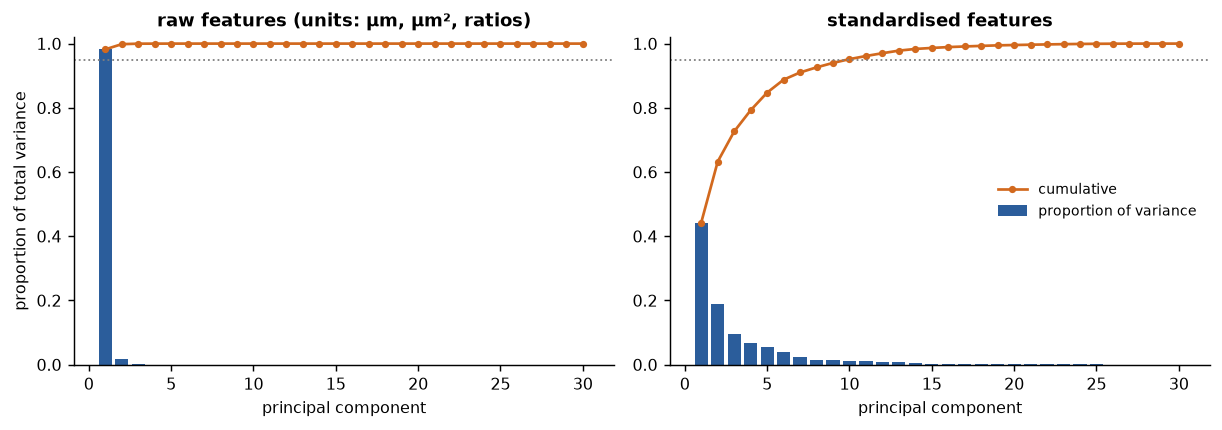

In [16]:
# Scree plots of the 30 breast-cancer features, raw (left) and standardised (right).
pca_raw = PCA().fit(X_raw); pca_std = PCA().fit(X_std)
cum_std = np.cumsum(pca_std.explained_variance_ratio_)
n95 = int(np.searchsorted(cum_std, 0.95) + 1)
print(f"RAW features:          PC1 explains {pca_raw.explained_variance_ratio_[0]:.1%}, PC2 {pca_raw.explained_variance_ratio_[1]:.1%};"
      f" PC1 is dominated by '{X_df.columns[np.argmax(np.abs(pca_raw.components_[0]))]}' (loading {np.abs(pca_raw.components_[0]).max():.3f})")
print(f"STANDARDISED features: PC1 explains {pca_std.explained_variance_ratio_[0]:.1%}, PC2 {pca_std.explained_variance_ratio_[1]:.1%}, PC3 {pca_std.explained_variance_ratio_[2]:.1%};"
      f" first two together {cum_std[1]:.1%}; {n95} components reach 95 %")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4))
for ax, p_, title in zip(axes, [pca_raw, pca_std], ["raw features (units: µm, µm², ratios)", "standardised features"]):
    comps = np.arange(1, 31)
    ax.bar(comps, p_.explained_variance_ratio_, color=BLUE, label="proportion of variance")
    ax.plot(comps, np.cumsum(p_.explained_variance_ratio_), "o-", color=ORANGE, ms=3, label="cumulative")
    ax.axhline(0.95, color=GREY, ls=":", lw=1); ax.set_xlabel("principal component"); ax.set_title(title); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("proportion of total variance"); axes[1].legend(frameon=False, fontsize=8, loc="center right")
fig.tight_layout()

<p class="caption"><b>Figure 10.</b> Scree plots. Left: on the raw features a single component carries about 98 % of the variance — and its loading vector is almost entirely <em>worst area</em>, the feature with the largest numbers. The "analysis" has found that area varies more than ratios do, which was known from the units of measurement. Right: after standardisation the first component carries about 44 %, the second about 19 %, the first two together about 63 %, and ten components are needed to reach 95 %. This is the honest picture of how many independent directions of variation the 30 features contain.</p>

<div class="box key"><h4>Standardise before PCA</h4><p>PCA maximises variance, and variance has units. A feature measured in µm² has a variance in µm⁴ and will dominate features measured as ratios whatever their biological importance. Unless all features share a unit and their variances are meaningfully comparable (pixel intensities of an image; voltages of the channels of one EEG), standardise first, which is the same as performing PCA on the <em>correlation</em> matrix instead of the covariance matrix. Jolliffe and Cadima's review discusses this and the other practical decisions of the method.<sup class="c"><a href="#r20">[20]</a></sup></p></div>

### 4.4 Loadings and the biplot

The entries of each eigenvector are the <strong>loadings</strong>: the weight of each original feature in the component. Reading them is how a component is interpreted. The <strong>biplot</strong> superimposes the scores of the cases on the first two components (points) with the loadings of the features (arrows): a long arrow means the feature contributes strongly to the two components; arrows pointing the same way mean correlated features; the position of a case along an arrow indicates a high or low value of that feature.

features with the largest |loading| on PC1:
                        PC1    PC2
mean concave points   0.261 -0.035
mean concavity        0.258  0.060
worst concave points  0.251 -0.008
mean compactness      0.239  0.152
worst perimeter       0.237 -0.200
worst concavity       0.229  0.098

features with the largest |loading| on PC2:
                           PC1    PC2
mean fractal dimension   0.064  0.367
fractal dimension error  0.103  0.280
worst fractal dimension  0.132  0.275
mean radius              0.219 -0.234
compactness error        0.170  0.233
mean area                0.221 -0.231


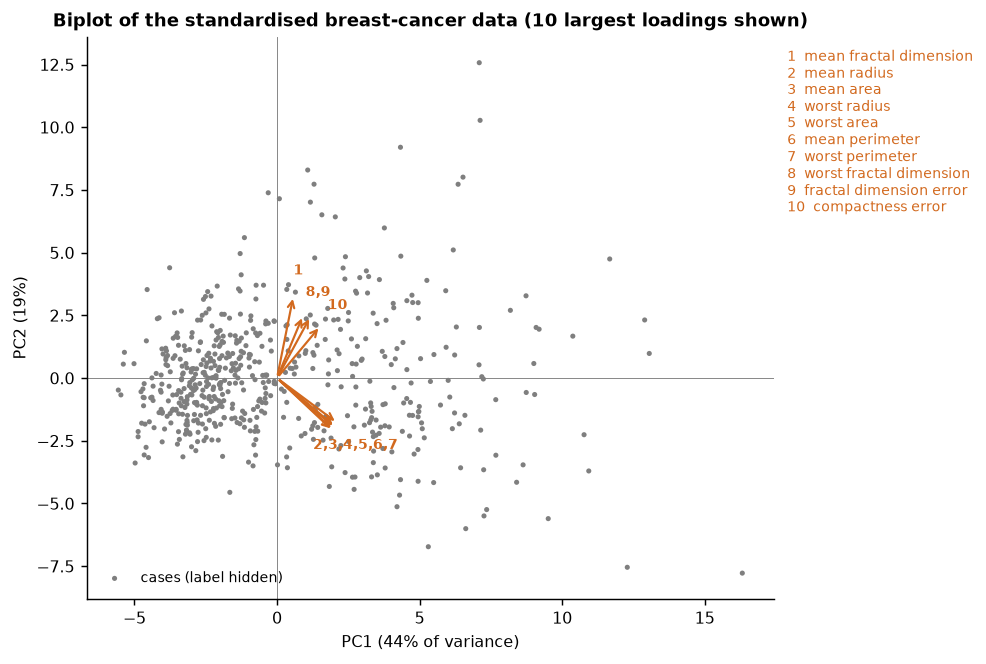

In [17]:
# Loadings of the first two standardised components, and the biplot.
loadings = pd.DataFrame(pca_std.components_[:2].T, index=X_df.columns, columns=["PC1", "PC2"])
print("features with the largest |loading| on PC1:"); print(loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(6).round(3).to_string())
print("\nfeatures with the largest |loading| on PC2:"); print(loadings.reindex(loadings["PC2"].abs().sort_values(ascending=False).index).head(6).round(3).to_string())
scores_std = pca_std.transform(X_std)

fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.scatter(scores_std[:, 0], scores_std[:, 1], s=8, color=GREY, edgecolor="none", label="cases (label hidden)")
scale = 9                                                             # stretch the unit arrows so they are visible among the scores
show = loadings.reindex((loadings ** 2).sum(1).sort_values(ascending=False).index).head(10)   # the ten most influential features
for name, (l1, l2) in show.iterrows():
    ax.annotate("", xy=(scale * l1, scale * l2), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=ORANGE, lw=1.2))
# arrows pointing in almost the same direction (within 8 degrees) share one label, so that labels do not overlap
ang = np.degrees(np.arctan2(show["PC2"].values, show["PC1"].values)); order = np.argsort(ang)
groups = [[order[0]]]
for prev, nxt in zip(order[:-1], order[1:]):
    groups[-1].append(nxt) if ang[nxt] - ang[prev] < 8 else groups.append([nxt])
for g in groups:
    nums = ",".join(str(i + 1) for i in sorted(g)); l1, l2 = show.iloc[g].mean()
    r = np.hypot(l1, l2); ax.text(scale * l1 + 1.0 * l1 / r, scale * l2 + 1.0 * l2 / r, nums, fontsize=8, color=ORANGE, weight="bold", ha="center", va="center")
ax.text(1.02, 0.98, "\n".join(f"{num}  {name}" for num, name in enumerate(show.index, start=1)), transform=ax.transAxes, fontsize=7.5, va="top", color=ORANGE)
ax.axhline(0, color=GREY, lw=0.5); ax.axvline(0, color=GREY, lw=0.5)
ax.set_xlabel(f"PC1 ({pca_std.explained_variance_ratio_[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({pca_std.explained_variance_ratio_[1]:.0%})")
ax.set_title("Biplot of the standardised breast-cancer data (10 largest loadings shown)"); ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(rect=(0, 0, 0.8, 1))

<p class="caption"><b>Figure 11.</b> Biplot. The 569 cases (grey) are plotted by their scores on PC1 and PC2; the numbered arrows are the loadings of the ten features that contribute most to the two components (names at the right), scaled for visibility. The six size features — mean and worst radius, area and perimeter (arrows 2–7) — point in almost exactly the same direction, to the right and slightly down: they are nearly interchangeable measurements of nuclear size, which is why PCA can compress them into one coordinate. The fractal-dimension features and <em>compactness error</em> (1, 8, 9, 10) point up and to the right, along PC2. PC1 is therefore a general "size and irregularity of the nucleus" axis (the loadings table shows that the concavity features load on it as strongly as the size features), and the cases at the right are large, irregular nuclei; PC2 contrasts fractal dimension and compactness with size — a shape-complexity axis independent of size. No label was used, yet the hidden diagnosis is largely a function of PC1 — which is why k-means found it in Section 2.8.</p>

The loadings table confirms the reading: the six largest loadings on PC1 all belong to the concavity, concave-points, compactness and perimeter features, with similar weights (about 0.23–0.26 each); PC1 is close to an average of them. On PC2 the largest loadings are the three fractal-dimension features and <em>compactness error</em> (positive) against <em>mean radius</em> and <em>mean area</em> (negative). An interpretation of this kind is the main scientific use of PCA: it tells the analyst that the 30 features measure, to a first approximation, two things.

### 4.5 PCA as a singular value decomposition; whitening

scikit-learn does not form the covariance matrix. It computes the <strong>singular value decomposition</strong> (SVD) of the centred data matrix, $\mathbf{X} = \mathbf{U} \boldsymbol{\Sigma} \mathbf{V}^\top$, where $\mathbf{V}$ holds the right singular vectors (the principal components, as columns), $\boldsymbol{\Sigma}$ the singular values $\sigma_j$, and $\mathbf{U}\boldsymbol{\Sigma}$ the scores. The connection is $\mathbf{X}^\top \mathbf{X} = \mathbf{V} \boldsymbol{\Sigma}^2 \mathbf{V}^\top$, so the eigenvalues of $\mathbf{S}$ are $\lambda_j = \sigma_j^2 / (n - 1)$. The SVD route is numerically more stable and avoids the $p \times p$ matrix, which matters when $p$ is in the thousands (genes) or tens of thousands (pixels).

<strong>Whitening</strong> (or sphering) goes one step further: divide each score by its standard deviation $\sqrt{\lambda_j}$, so that the transformed data have identity covariance — every direction has unit variance and all are uncorrelated. Whitening throws away the variance information that PCA ranks by, which makes it useless for choosing components but essential as the first step of ICA (Section 5), where the directions of interest are not those of largest variance.

In [18]:
# PCA via SVD: singular values -> eigenvalues; whitening -> identity covariance.
Xc = X_std - X_std.mean(axis=0)
U, sing, Vt = np.linalg.svd(Xc, full_matrices=False)
print("eigenvalues from SVD, sigma^2/(n-1):", (sing[:4] ** 2 / (len(Xc) - 1)).round(3))
print("eigenvalues from sklearn PCA:        ", pca_std.explained_variance_[:4].round(3))
print("first component from SVD vs PCA agree up to sign:", np.allclose(np.abs(Vt[0]), np.abs(pca_std.components_[0])))

Z_white = PCA(n_components=5, whiten=True, random_state=0).fit_transform(X_std)
print("\ncovariance of the first five scores WITHOUT whitening (diagonal = eigenvalues, off-diagonal = 0):\n", np.cov(scores_std[:, :5].T).round(2))
print("covariance of the five whitened scores (identity):\n", np.cov(Z_white.T).round(2))

eigenvalues from SVD, sigma^2/(n-1): [13.305  5.701  2.823  1.984]
eigenvalues from sklearn PCA:         [13.305  5.701  2.823  1.984]
first component from SVD vs PCA agree up to sign: True

covariance of the first five scores WITHOUT whitening (diagonal = eigenvalues, off-diagonal = 0):
 [[13.3  -0.   -0.   -0.    0.  ]
 [-0.    5.7   0.    0.   -0.  ]
 [-0.    0.    2.82 -0.    0.  ]
 [-0.    0.   -0.    1.98 -0.  ]
 [ 0.   -0.    0.   -0.    1.65]]
covariance of the five whitened scores (identity):
 [[ 1. -0. -0. -0.  0.]
 [-0.  1. -0.  0. -0.]
 [-0. -0.  1. -0.  0.]
 [-0.  0. -0.  1. -0.]
 [ 0. -0.  0. -0.  1.]]


The singular values squared and divided by $n - 1$ are the eigenvalues to every printed digit, and the first singular vector equals the first component up to sign. The covariance of the scores is diagonal — the components are uncorrelated by construction, with the eigenvalues on the diagonal — and after whitening it is the identity.

### 4.6 PCA for visualisation and as preprocessing

Two practical uses follow directly. First, <strong>visualisation</strong>: projecting high-dimensional data onto the first two components gives the two-dimensional picture that retains the most variance, which is the standard first look at any dataset with more than three features. The cell does this for the 1,797 handwritten digits of Unit 1, 64 pixels each.<sup class="c"><a href="#r21">[21]</a></sup> Second, <strong>preprocessing</strong>: replacing the $p$ features by the first $q$ components before a supervised classifier removes redundancy (correlated features become one), reduces noise (the low-variance components often are noise) and speeds up distance-based methods such as k-NN, whose cost grows with $p$. The second cell measures the cross-validated accuracy of k-NN on the breast-cancer data as a function of the number of components retained — with the PCA fitted <em>inside</em> the cross-validation folds, because fitting it on all the data first would let the test folds influence the components (the leakage of Supplement S1, in a form that is often overlooked because PCA uses no labels).

variance retained by two components: 28.5%; components needed for 90 %: 21 of 64


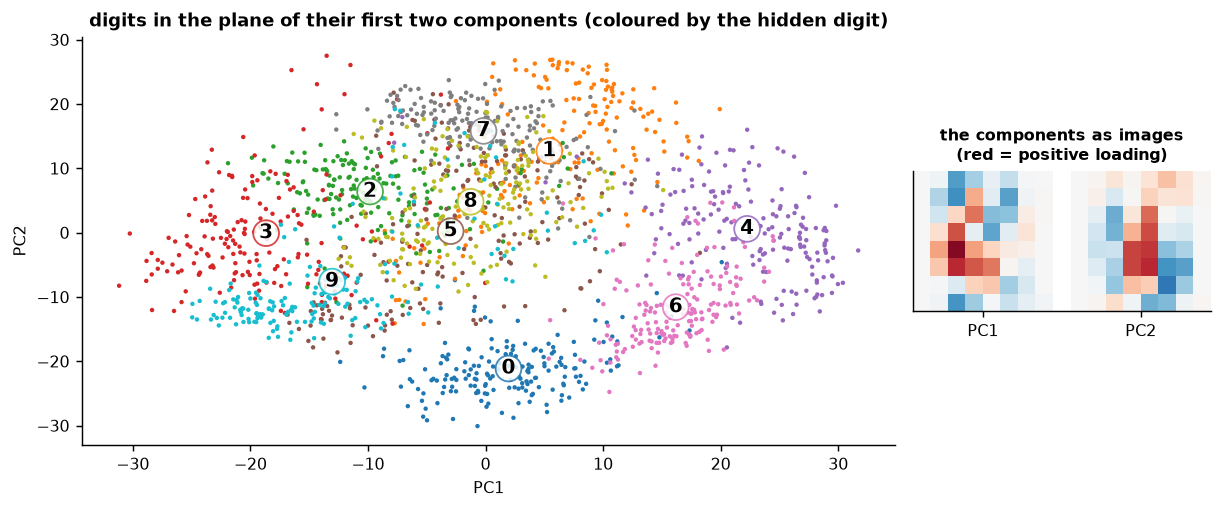

In [19]:
# PCA for visualisation: 1,797 digit images (64 pixels) projected onto their first two principal components.
digits = datasets.load_digits()
pca_dig = PCA(n_components=2, random_state=0).fit(digits.data)
Z_dig = pca_dig.transform(digits.data)
print(f"variance retained by two components: {pca_dig.explained_variance_ratio_.sum():.1%};"
      f" components needed for 90 %: {int(np.searchsorted(np.cumsum(PCA().fit(digits.data).explained_variance_ratio_), 0.90) + 1)} of 64")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 4), gridspec_kw={"width_ratios": [3, 1.1]})
cmap = plt.get_cmap("tab10")
for d in range(10):
    m = digits.target == d
    axes[0].scatter(Z_dig[m, 0], Z_dig[m, 1], s=6, color=cmap(d), edgecolor="none", label=str(d))
    axes[0].text(*Z_dig[m].mean(0), str(d), fontsize=11, weight="bold", ha="center", va="center",
                 bbox=dict(boxstyle="circle,pad=0.15", fc="white", ec=cmap(d), alpha=0.85))
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title("digits in the plane of their first two components (coloured by the hidden digit)")
# the two components themselves, drawn as 8 x 8 images: what PC1 and PC2 'look like'
comp_img = np.hstack([pca_dig.components_[0].reshape(8, 8), np.full((8, 1), np.nan), pca_dig.components_[1].reshape(8, 8)])
axes[1].imshow(comp_img, cmap="RdBu_r", vmin=-0.4, vmax=0.4); axes[1].set_xticks([3.5, 12.5]); axes[1].set_xticklabels(["PC1", "PC2"]); axes[1].set_yticks([])
axes[1].set_title("the components as images\n(red = positive loading)", fontsize=9)
fig.tight_layout()

<p class="caption"><b>Figure 12.</b> Left: the 1,797 digits in the plane of their first two components, coloured by the true digit (hidden from PCA). Two components retain less than a third of the variance, yet the classes already form recognisable regions: zeros at the bottom, fours and sixes at the right, threes, twos and nines at the left, with fives and eights overlapping in the centre. Right: the two components displayed as 8 × 8 images. PC1 contrasts a vertical stroke through the centre of the image (red) with the pixels on either side of it (blue) — it separates digits with a filled centre from those with an empty one. A component of an image dataset is itself an image, and reading it this way is the pixel-space equivalent of reading a loadings table.</p>

components           1.0000  2.0000  3.0000  4.0000  5.0000  7.0000  10.0000  15.0000  20.0000  30.0000
CV accuracy of 5-NN  0.9034  0.9385  0.9385  0.9596  0.9596  0.9614   0.9649   0.9649   0.9631   0.9649

5-NN on all 30 standardised features, no PCA: 0.9649


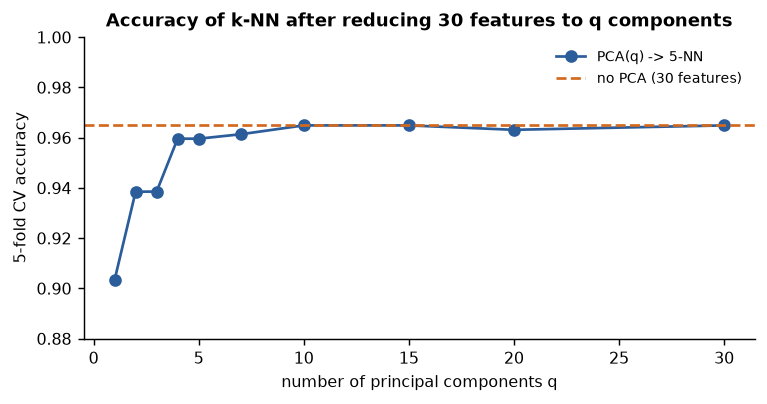

In [20]:
# PCA as preprocessing: 5-fold cross-validated accuracy of 5-NN on the breast-cancer data vs. number of components retained.
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
n_comps = [1, 2, 3, 4, 5, 7, 10, 15, 20, 30]
acc = [cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=q, random_state=0), KNeighborsClassifier(5)), X_raw, y_hidden, cv=cv).mean() for q in n_comps]
acc_full = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X_raw, y_hidden, cv=cv).mean()
res = pd.DataFrame({"components": n_comps, "CV accuracy of 5-NN": np.round(acc, 4)})
print(res.T.to_string(header=False)); print(f"\n5-NN on all 30 standardised features, no PCA: {acc_full:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(n_comps, acc, "o-", color=BLUE, label="PCA(q) -> 5-NN")
ax.axhline(acc_full, color=ORANGE, ls="--", label="no PCA (30 features)")
ax.set_xlabel("number of principal components q"); ax.set_ylabel("5-fold CV accuracy"); ax.set_ylim(0.88, 1.0); ax.legend(frameon=False, fontsize=8)
ax.set_title("Accuracy of k-NN after reducing 30 features to q components"); fig.tight_layout()

<p class="caption"><b>Figure 13.</b> Cross-validated accuracy of a 5-nearest-neighbour classifier trained on the first $q$ principal components of the standardised features. One component — the "size and irregularity" axis of Figure 11 — already gives about 90 %; two give about 94 %; from five components onward the curve is within half a percentage point of the full 30 features (dashed, about 96 %), and from ten components it equals it. Twenty of the thirty dimensions can be discarded at no cost — and twenty-five at a cost of half a point — because they carry variation that is either redundant or irrelevant to the diagnosis.</p>

Note the use of the labels here. PCA itself used none — the components are the same whether or not $\mathbf{y}$ exists — but the <em>evaluation</em> of how many components to keep for a supervised task necessarily uses the labels, through the cross-validated accuracy. That is legitimate as long as the PCA is refitted inside each fold, as the pipeline does.

<div class="exercise"><h4>Exercise 4</h4><p>Replace <code>KNeighborsClassifier(5)</code> with the logistic regression of Unit 2 (<code>LogisticRegression(max_iter=1000)</code>) and re-run. Does the accuracy depend on $q$ in the same way? Linear classifiers are less affected by irrelevant dimensions than k-NN; propose why, using the curse of dimensionality from Unit 3.</p></div>

### 4.7 Limits of PCA, and t-SNE and UMAP for visualisation

PCA is <strong>linear</strong>: the components are weighted sums of the features, and the subspace is flat. Data that lie on a curved surface — a spiral, a sphere, the half-moons — are poorly summarised by any flat subspace, and PCA will report many components where one curved coordinate would do. Kernel PCA and the autoencoders of Unit 6 are the nonlinear extensions.

More important, and more often forgotten: <strong>variance is not information</strong>. PCA ranks directions by how much the data spread along them, not by how relevant that spread is to any question. If the difference between two groups of patients lies along a direction of small variance — a subtle biomarker — while a large, irrelevant source of variation (age, batch, instrument) dominates, the first components will describe the irrelevant source and the biomarker will be in a late component or discarded. The cell builds exactly this situation.

proportion of variance: [0.936 0.064] | PC1 loadings: [ 1.    -0.011]
CV accuracy of logistic regression on PC1 only               : 0.523
CV accuracy of logistic regression on PC2 only               : 1.000
CV accuracy of logistic regression on both original features : 1.000


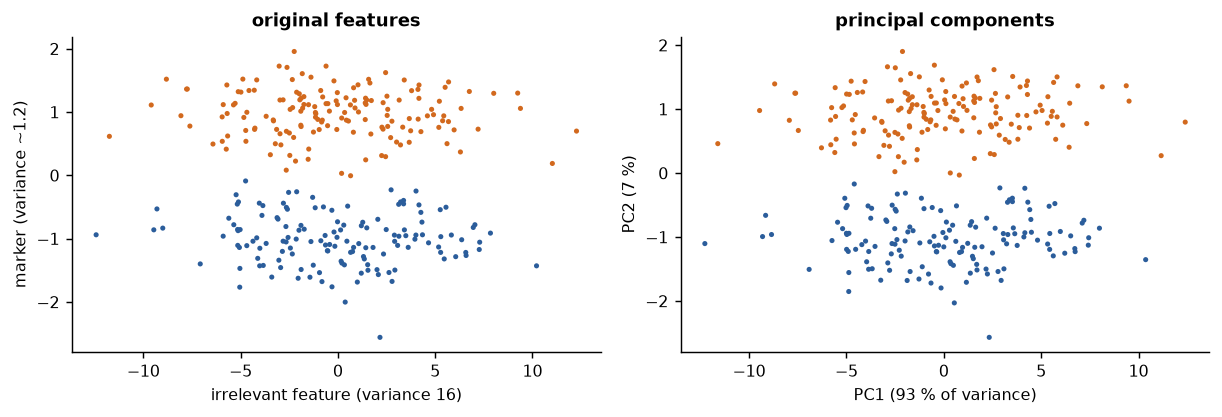

In [21]:
# Variance is not information: two groups separated along a LOW-variance direction, hidden behind a high-variance irrelevant one.
rng = np.random.default_rng(0)
n = 300
irrelevant = rng.normal(0, 4.0, n)                                # e.g. patient age: large spread, unrelated to the groups
group = rng.integers(0, 2, n)
marker = np.where(group == 0, -1.0, 1.0) + rng.normal(0, 0.4, n)   # the informative feature: small spread, separates the groups
X_vi = np.c_[irrelevant, marker]
pca_vi = PCA().fit(X_vi); Z_vi = pca_vi.transform(X_vi)
print("proportion of variance:", pca_vi.explained_variance_ratio_.round(3), "| PC1 loadings:", pca_vi.components_[0].round(3))
from sklearn.linear_model import LogisticRegression
for name, F in [("PC1 only", Z_vi[:, :1]), ("PC2 only", Z_vi[:, 1:]), ("both original features", X_vi)]:
    print(f"CV accuracy of logistic regression on {name:23s}: {cross_val_score(LogisticRegression(), F, group, cv=cv).mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
for ax, (Fx, Fy, xl, yl, title) in zip(axes, [(X_vi[:, 0], X_vi[:, 1], "irrelevant feature (variance 16)", "marker (variance ~1.2)", "original features"),
                                               (Z_vi[:, 0], Z_vi[:, 1], "PC1 (93 % of variance)", "PC2 (7 %)", "principal components")]):
    ax.scatter(Fx, Fy, c=[BLUE if g == 0 else ORANGE for g in group], s=8, edgecolor="none"); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(title)
fig.tight_layout()

<p class="caption"><b>Figure 14.</b> Left: two groups (colours hidden from PCA) separated cleanly along a feature of small variance, while an unrelated feature has about fourteen times the variance. Right: PCA puts almost all the variance into PC1, which is essentially the irrelevant feature; the group separation survives only in PC2. An analyst who kept "the component that explains 93 % of the variance" would have discarded the only informative direction, and a classifier on PC1 alone performs at chance while one on PC2 alone is nearly perfect, as the printout shows.</p>

For <strong>visualisation</strong> of high-dimensional data in two dimensions, two nonlinear methods have largely displaced PCA in the biomedical literature: <strong>t-SNE</strong> (t-distributed stochastic neighbour embedding),<sup class="c"><a href="#r22">[22]</a></sup> which places points in the plane so that neighbours in the original space remain neighbours, and <strong>UMAP</strong> (uniform manifold approximation and projection),<sup class="c"><a href="#r23">[23]</a></sup> which does the same faster and with a stronger claim to preserve coarse structure. Both produce the striking "islands" plots of single-cell RNA sequencing. Both are <em>for visualisation only</em>: the distances between islands and the sizes and shapes of islands are not meaningful, the result depends on tuning parameters (perplexity, number of neighbours) and on the random seed, and new points cannot be placed in the map without recomputing it. They should never be used as preprocessing for clustering or classification, and clusters seen in them should be confirmed in the original feature space. scikit-learn provides <code>sklearn.manifold.TSNE</code>; UMAP is a separate package not used here.

<div class="box warn"><h4>Common misconception</h4><p>"The first two components explain only 30 % of the variance, so the PCA failed." A low proportion of variance in two components means the data are genuinely high-dimensional, which is a finding, not a failure; and, as Figure 14 shows, a high proportion in one component can be a failure, when that component is irrelevant. The proportion of variance measures compression, not relevance.</p></div>

## 5. Independent component analysis

### 5.1 The cocktail-party problem; independence versus uncorrelatedness

Two people speak at once in a room with two microphones. Each microphone records a different weighted sum of the two voices, the weights depending on the distances. Given only the two recordings, can the two voices be recovered? This is the <strong>cocktail-party problem</strong>, the prototype of <strong>blind source separation</strong>: $m$ observed signals $\mathbf{x}(t)$ are modelled as an unknown linear mixture of $m$ unknown source signals $\mathbf{s}(t)$,

<div class="eq">$$\mathbf{x} = \mathbf{A}\,\mathbf{s}, \qquad \hat{\mathbf{s}} = \mathbf{W}\,\mathbf{x}$$
<span class="where">where $\mathbf{A}$ is the $m \times m$ <em>mixing matrix</em>, and the task is to find an <em>unmixing matrix</em> $\mathbf{W} \approx \mathbf{A}^{-1}$ from the observations alone, with no knowledge of $\mathbf{A}$ or of the sources except one assumption: the sources are <strong>statistically independent</strong>.</span></div>

Independent component analysis (ICA) is the family of methods that solve this problem. The name and the formal definition are due to Comon (1994);<sup class="c"><a href="#r24">[24]</a></sup> the algorithm that made it practical, Infomax, is due to Bell and Sejnowski (1995);<sup class="c"><a href="#r25">[25]</a></sup> and the fast fixed-point algorithm used below, FastICA, to Hyvärinen and Oja, whose 2000 review is the standard introduction.<sup class="c"><a href="#r26">[26]</a></sup>

The distinction that makes ICA different from PCA is between <em>uncorrelated</em> and <em>independent</em>. Two variables are uncorrelated when their covariance is zero — a statement about second moments only. They are independent when their joint distribution factorises, $p(s_1, s_2) = p(s_1)\,p(s_2)$ — a statement about all moments. Independence implies uncorrelatedness; the converse holds only for Gaussian variables. PCA finds uncorrelated components, and for a Gaussian signal that is all there is to find; for non-Gaussian signals there is a stronger structure, independence, and PCA does not see it.

### 5.2 Non-Gaussianity as the lever

Why can independence be recovered at all? The argument is the central limit theorem run backwards. A sum of independent random variables is <em>more Gaussian</em> than any of its terms: that is what the theorem says. Each observed mixture $x_j = \sum_l a_{jl} s_l$ is such a sum, so the mixtures are closer to Gaussian than the sources. Conversely, among all linear combinations $\mathbf{w}^\top \mathbf{x}$ of the observations, the <em>least</em> Gaussian ones must be the original sources (up to scale). ICA therefore searches for the directions $\mathbf{w}$ that maximise a measure of non-Gaussianity, and it works exactly to the extent that the sources are non-Gaussian — <strong>at most one source may be Gaussian</strong>, or the problem has no unique solution.

Two measures of non-Gaussianity are in use. <strong>Kurtosis</strong>, the standardised fourth moment $\kappa = \mathbb{E}[s^4]/\mathbb{E}[s^2]^2 - 3$, is zero for a Gaussian, positive for "peaky" distributions with heavy tails (speech, spikes, ECG) and negative for flat ones (a square wave, a uniform variable); it is simple but sensitive to outliers. <strong>Negentropy</strong>, the difference between the entropy of a Gaussian with the same variance and the entropy of the variable, is zero for a Gaussian and positive otherwise, is robust, and is what FastICA approximates with a smooth contrast function such as $\log\cosh$. FastICA first <em>whitens</em> the data with PCA (Section 4.5), so that the remaining problem is to find a <em>rotation</em>, then finds the rotation one direction at a time by a fixed-point iteration on the chosen contrast.

### 5.3 FastICA on three synthetic sources: PCA fails, ICA succeeds

Three sources — a sine, a square wave and a sawtooth — are mixed by a random $3 \times 3$ matrix into three observed channels. PCA and FastICA are each asked for three components, and the recovered components are compared with the true sources by their absolute correlation.

In [22]:
# Three independent sources, a random mixing matrix, and the attempt to unmix with PCA and with FastICA.
from sklearn.decomposition import FastICA
from scipy import signal, stats
t = np.linspace(0, 8, 2000)
rng = np.random.default_rng(0)
S_true = np.c_[np.sin(2 * np.pi * 1.0 * t), np.sign(np.sin(2 * np.pi * 0.6 * t + 1)), signal.sawtooth(2 * np.pi * 0.4 * t)]
S_true += 0.05 * rng.normal(size=S_true.shape); S_true /= S_true.std(axis=0)      # unit-variance sources
A_mix = rng.normal(size=(3, 3))                                                     # unknown mixing matrix
X_mix = S_true @ A_mix.T                                                            # the three observed channels

print("kurtosis of the sources :", stats.kurtosis(S_true).round(2), " (all far from 0: non-Gaussian)")
print("kurtosis of the mixtures:", stats.kurtosis(X_mix).round(2), " (closer to 0: mixing makes signals more Gaussian)")
S_pca = PCA(n_components=3, random_state=0).fit_transform(X_mix)
ica = FastICA(n_components=3, random_state=0, whiten="unit-variance")
S_ica = ica.fit_transform(X_mix)
def match_table(S_rec, name):
    '''|correlation| between each true source (rows) and each recovered component (columns).'''
    C = np.abs(np.corrcoef(S_true.T, S_rec.T)[:3, 3:])
    return pd.DataFrame(C, index=["sine", "square", "sawtooth"], columns=[f"{name} {j+1}" for j in range(3)]).round(3)
print("\n", match_table(S_pca, "PC").to_string(), "\n\n", match_table(S_ica, "IC").to_string())
print(f"\nFastICA converged in {ica.n_iter_} iterations; best |correlation| per source: PCA {np.abs(np.corrcoef(S_true.T, S_pca.T)[:3, 3:]).max(1).round(2)}, ICA {np.abs(np.corrcoef(S_true.T, S_ica.T)[:3, 3:]).max(1).round(3)}")

kurtosis of the sources : [-1.49 -1.99 -1.24]  (all far from 0: non-Gaussian)
kurtosis of the mixtures: [-1.12 -1.23 -0.78]  (closer to 0: mixing makes signals more Gaussian)

            PC 1   PC 2   PC 3
sine      0.746  0.569  0.346
square    0.706  0.583  0.402
sawtooth  0.118  0.530  0.840 

            IC 1   IC 2   IC 3
sine      1.000  0.010  0.024
square    0.031  0.066  0.997
sawtooth  0.067  0.998  0.014

FastICA converged in 5 iterations; best |correlation| per source: PCA [0.75 0.71 0.84], ICA [1.    0.997 0.998]


The kurtosis printout shows the central-limit argument at work: every source has a kurtosis well below zero (a sine, a square wave and a sawtooth are all flat-topped), and every mixture is closer to zero. The correlation tables show the result. Each PCA component is a blend of the three sources, with correlations spread across the row — PCA has found uncorrelated directions, which is not enough. Each ICA component correlates almost perfectly (above 0.99) with exactly one source and negligibly with the other two: the sources have been recovered without any knowledge of the mixing matrix. The figure shows the signals.

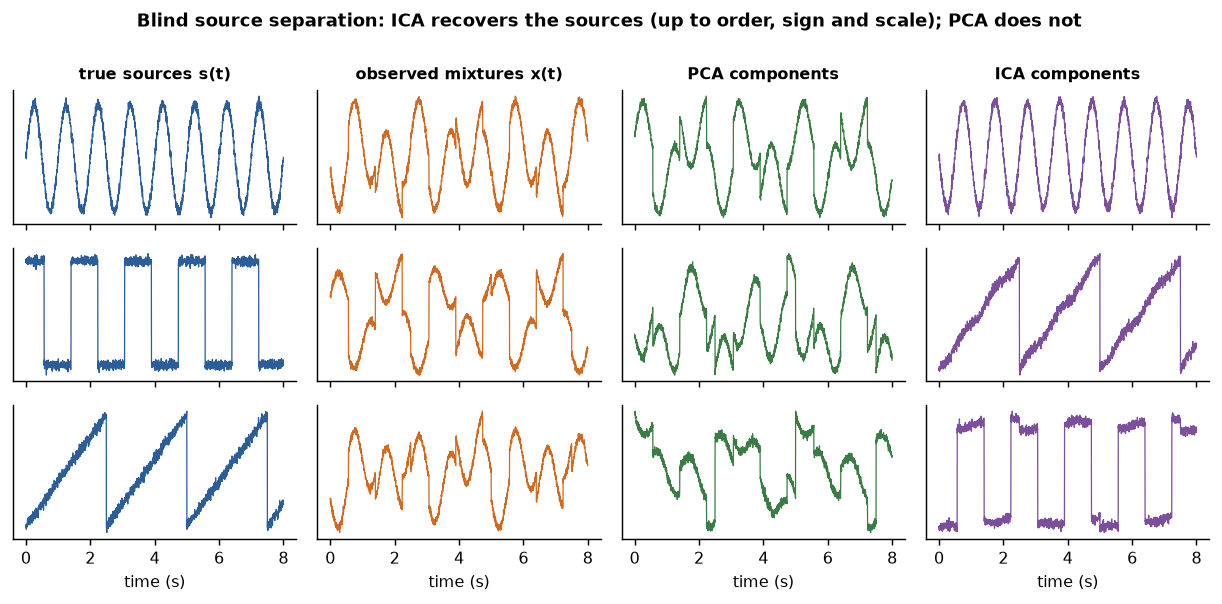

In [23]:
# The sources, the mixtures, and the components recovered by PCA and by ICA.
fig, axes = plt.subplots(3, 4, figsize=(9.5, 4.6), sharex=True)
panels = [("true sources s(t)", S_true), ("observed mixtures x(t)", X_mix), ("PCA components", S_pca), ("ICA components", S_ica)]
for col, (title, M) in enumerate(panels):
    for row in range(3):
        axes[row, col].plot(t, M[:, row], color=PALETTE[col], lw=0.7); axes[row, col].set_yticks([])
    axes[0, col].set_title(title, fontsize=9); axes[2, col].set_xlabel("time (s)")
fig.suptitle("Blind source separation: ICA recovers the sources (up to order, sign and scale); PCA does not", fontsize=10, weight="bold", y=1.0)
fig.tight_layout()

<p class="caption"><b>Figure 15.</b> Columns: the three sources; the three recorded mixtures, each a weighted sum of all sources; the three principal components, which are still mixtures (a sine with a square wave superposed, and so on); and the three independent components, which are the sources again — but in a different order and, for some, upside down. Compare the row order of the first and last columns.</p>

**The two ambiguities.** ICA cannot recover the <em>order</em> of the sources — any permutation of the rows of $\mathbf{s}$ with the corresponding permutation of the columns of $\mathbf{A}$ gives the same $\mathbf{x}$ — nor their <em>scale and sign</em>, since multiplying a source by $c$ and the corresponding column of $\mathbf{A}$ by $1/c$ changes nothing. FastICA fixes the scale by returning unit-variance components and leaves the order and sign arbitrary. Consequently the "first independent component" means nothing (unlike the first principal component), the components must be identified by their content — their waveform, their spatial pattern over channels, their correlation with a reference — and that identification is the step where the analyst's knowledge enters.

### 5.4 Biomedical application: removing an artefact from a multichannel recording

Electrophysiological recordings — the EEG with its 19 to 256 scalp electrodes, the multi-lead ECG, the magnetoencephalogram — are the natural home of ICA, because each electrode records a linear mixture, through the conducting tissues, of several sources: the neural or cardiac activity of interest, and artefacts such as eye blinks, eye movements, muscle activity, the heartbeat seen by the EEG, electrode drift and mains interference. Makeig and colleagues first applied ICA to EEG in 1996,<sup class="c"><a href="#r27">[27]</a></sup> and Jung and colleagues showed in 2000 that artefact components could be identified and removed — the recording is reconstructed from the remaining components — more selectively than by rejecting contaminated epochs or by regression on a reference channel.<sup class="c"><a href="#r28">[28]</a></sup> This <em>ICA-based artefact rejection</em> is today a standard step in EEG preprocessing pipelines.

The cell simulates the situation in miniature: a clean "ECG" source, an eye-blink-like artefact (three slow Gaussian bumps) and a slow baseline drift are mixed into four channels with different weights, FastICA is run with three components, the artefact component is identified by its correlation with the known artefact (in practice: by its waveform and its spatial pattern), set to zero, and the channels are reconstructed. The quality of the removal is measured as the root-mean-square error between the cleaned channel and the channel as it would have been without the artefact.

In [24]:
# Simulated 4-channel recording: ECG + eye-blink-like artefact + baseline drift. ICA removes the artefact component.
fs = 250; tt = np.arange(0, 10, 1 / fs); rng = np.random.default_rng(0)
beats = np.arange(0.4, 10, 0.8)                                                                   # 75 beats per minute
ecg = sum(np.exp(-((tt - b) / 0.012) ** 2) - 0.3 * np.exp(-((tt - b - 0.05) / 0.02) ** 2) + 0.25 * np.exp(-((tt - b + 0.2) / 0.06) ** 2) for b in beats)
blink = sum(np.exp(-((tt - b) / 0.12) ** 2) for b in [1.5, 4.2, 7.8])                            # three slow, large deflections
drift = 0.3 * np.sin(2 * np.pi * 0.2 * tt)                                                        # respiration-like baseline wander
sources = np.c_[ecg, blink, drift]
M_mix = np.array([[1.0, 0.2, 0.3], [0.8, 1.2, 0.2], [0.6, 0.6, 0.5], [0.3, 1.5, 0.4]])             # 4 channels x 3 sources
channels = sources @ M_mix.T + 0.03 * rng.normal(size=(len(tt), 4))
clean_target = channels - np.outer(blink, M_mix[:, 1])                                           # what each channel would be without the blink

ica_ecg = FastICA(n_components=3, random_state=0, whiten="unit-variance", max_iter=1000)
comps = ica_ecg.fit_transform(channels)
corr = np.abs(np.corrcoef(sources.T, comps.T)[:3, 3:])
k_art = int(np.argmax(corr[1]))                                    # the component most correlated with the blink
print("|corr| of components with (ecg, blink, drift):\n", pd.DataFrame(corr, index=["ecg", "blink", "drift"], columns=[f"IC{j+1}" for j in range(3)]).round(3).to_string())
comps_clean = comps.copy(); comps_clean[:, k_art] = 0              # remove the artefact component ...
cleaned = ica_ecg.inverse_transform(comps_clean)                   # ... and reconstruct the channels
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean(axis=0))
report = pd.DataFrame({"blink weight": M_mix[:, 1], "RMSE before": rmse(channels, clean_target), "RMSE after ICA": rmse(cleaned, clean_target)}, index=[f"ch{j+1}" for j in range(4)]).round(3)
print(f"\nartefact component identified: IC{k_art + 1}\n", report.to_string())

|corr| of components with (ecg, blink, drift):
          IC1    IC2    IC3
ecg    0.976  0.021  0.011
blink  0.022  0.020  0.992
drift  0.037  0.922  0.008

artefact component identified: IC3
      blink weight  RMSE before  RMSE after ICA
ch1           0.2        0.042           0.021
ch2           1.2        0.255           0.083
ch3           0.6        0.127           0.044
ch4           1.5        0.319           0.104


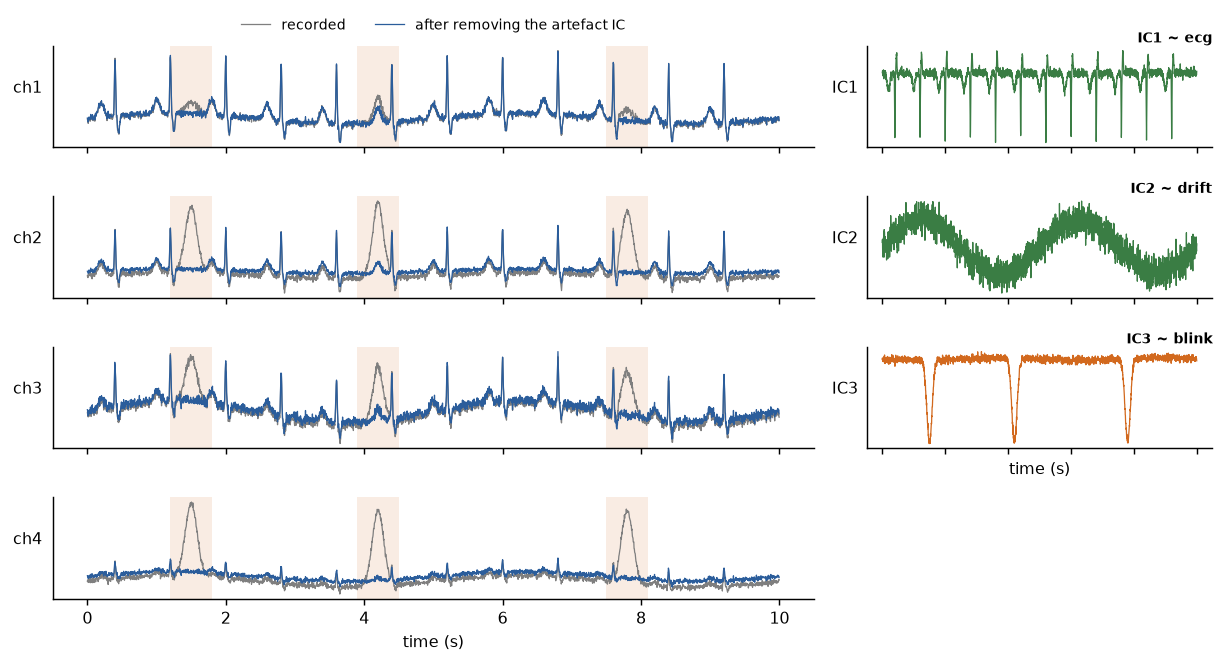

In [25]:
# The four channels before and after removal of the artefact component, and the three components.
fig, axes = plt.subplots(4, 2, figsize=(9.5, 5.2), sharex=True, gridspec_kw={"width_ratios": [2.2, 1]})
for j in range(4):
    axes[j, 0].plot(tt, channels[:, j], color=GREY, lw=0.7, label="recorded"); axes[j, 0].plot(tt, cleaned[:, j], color=BLUE, lw=0.7, label="after removing the artefact IC")
    axes[j, 0].set_ylabel(f"ch{j+1}", rotation=0, labelpad=14); axes[j, 0].set_yticks([])
    for b in [1.5, 4.2, 7.8]: axes[j, 0].axvspan(b - 0.3, b + 0.3, color=ORANGE, alpha=0.12, lw=0)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2); axes[3, 0].set_xlabel("time (s)")
names = ["ecg", "blink", "drift"]
for j in range(3):
    axes[j, 1].plot(tt, comps[:, j], color=ORANGE if j == k_art else GREEN, lw=0.7); axes[j, 1].set_yticks([])
    axes[j, 1].set_ylabel(f"IC{j+1}", rotation=0, labelpad=12); axes[j, 1].set_title(f"IC{j+1} ~ {names[int(np.argmax(corr[:, j]))]}", fontsize=8, loc="right", pad=2)
axes[3, 1].axis("off"); axes[2, 1].set_xlabel("time (s)")
fig.tight_layout()

<p class="caption"><b>Figure 16.</b> Left: the four recorded channels (grey) and the same channels after the artefact component was zeroed and the recording reconstructed (blue). The three shaded intervals mark the blinks; in the recorded channels they appear as slow deflections of varying size — large in channels 2 and 4, which carry the largest blink weight, small in channel 1 — and in the cleaned channels they are largely gone, while the beats are untouched. Right: the three independent components, one of which (orange) is the blink; the others are the ECG and the drift. The table above reports the root-mean-square deviation of each channel from its blink-free version, which falls by a factor of two to three; the residual is the price of imperfect separation in the presence of noise, and of the sign/scale indeterminacy being absorbed into the reconstruction.</p>

<div class="box key"><h4>Why ICA and not filtering?</h4><p>A blink and a heartbeat overlap in frequency, so no frequency filter removes one without distorting the other. ICA separates them by a different property — their statistical independence and their different <em>spatial</em> signatures across channels — which is why it needs several channels and a filter needs one. The same logic applies to the removal of the cardiac artefact from EEG, of muscle artefact, and of the maternal ECG from an abdominal fetal ECG recording.</p></div>

### 5.5 PCA versus ICA

| | PCA | ICA |
|---|---|---|
| Criterion | Maximal variance / minimal reconstruction error | Maximal statistical independence (non-Gaussianity) |
| Statistics used | Second order only (covariance) | Higher order (kurtosis, negentropy) |
| Components are | Uncorrelated and <em>orthogonal</em> | Independent; not orthogonal in general |
| Ordering | By variance explained; the first component is special | None; components are identified by content |
| Sign / scale | Sign arbitrary; scale = standard deviation $\sqrt{\lambda}$ | Sign and scale arbitrary (unit variance by convention) |
| Solution | Unique, closed form (eigen-decomposition / SVD) | Iterative; depends on the start and the contrast function; at most one Gaussian source |
| Typical use | Compression, visualisation, noise reduction, preprocessing | Blind source separation: EEG/ECG/MEG artefacts, fMRI networks, hyperspectral unmixing |
| Assumes | Linearity; variance = relevance | Linearity; independent, non-Gaussian sources; as many channels as sources |

## 6. Other methods, briefly

**Gaussian mixture models and the EM algorithm.** Model the data as a weighted sum of $k$ Gaussian densities, $p(\mathbf{x}) = \sum_j \pi_j\, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)$, and fit the weights, means and covariances by maximum likelihood. The fitting algorithm is <strong>expectation–maximisation</strong> (EM),<sup class="c"><a href="#r29">[29]</a></sup> which alternates an E-step — compute, for every point, the posterior probability (<em>responsibility</em>) of belonging to each component — and an M-step — re-estimate each component's parameters as responsibility-weighted statistics. This is <em>soft k-means</em> exactly: k-means is the limit of EM for Gaussians with equal spherical covariances when the responsibilities are forced to 0 or 1. Because each component has its own covariance, mixtures handle clusters of different size, spread and orientation (the failure of Figure 5a), and because the model is a density, the number of components can be chosen by a likelihood-based criterion (BIC). <code>sklearn.mixture.GaussianMixture</code>.

**DBSCAN.** Density-based spatial clustering of applications with noise<sup class="c"><a href="#r30">[30]</a></sup> defines a cluster as a maximal set of points connected through regions of high density: a point is a <em>core</em> point if at least <code>min_samples</code> points lie within distance <code>eps</code> of it; core points within <code>eps</code> of each other are in the same cluster; non-core points within reach of a core point join it; everything else is labelled <em>noise</em>. It needs no $k$, finds clusters of any shape, and is the only method here that can refuse to assign a point. Its weaknesses are the sensitivity to <code>eps</code> and its single density scale: clusters of different densities cannot both be found with one <code>eps</code>. <code>sklearn.cluster.DBSCAN</code>.

**Spectral clustering.** Build a similarity graph on the points (k-nearest-neighbour or Gaussian-kernel weights), compute the first few eigenvectors of the graph Laplacian, and run k-means on the rows of the eigenvector matrix. The eigenvectors embed the data in a space where connected regions of the graph become compact groups, so k-means can then find clusters of arbitrary shape; the method is a relaxation of the graph-cut problem. It is accurate on moderate $n$ and expensive beyond, because of the eigen-decomposition. <code>sklearn.cluster.SpectralClustering</code>.

k-means, k = 2                       clusters found: 2, noise points: 0
Gaussian mixture, 2 comp.            clusters found: 2, noise points: 0
DBSCAN, eps 0.2, min_samples 5       clusters found: 2, noise points: 0
spectral, 10-NN graph, k = 2         clusters found: 2, noise points: 0


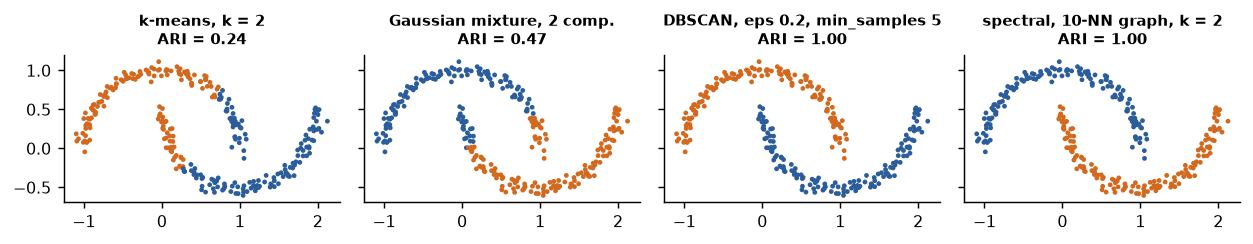

In [26]:
# The half-moons of Section 2.7 clustered by k-means, a Gaussian mixture, DBSCAN and spectral clustering.
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN, SpectralClustering
X_mo, y_mo = make_moons(n_samples=300, noise=0.05, random_state=0)
methods = [("k-means, k = 2", KMeans(2, n_init=10, random_state=0)),
           ("Gaussian mixture, 2 comp.", GaussianMixture(2, random_state=0)),
           ("DBSCAN, eps 0.2, min_samples 5", DBSCAN(eps=0.2, min_samples=5)),
           ("spectral, 10-NN graph, k = 2", SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0))]
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.7), sharex=True, sharey=True)
for ax, (name, mdl) in zip(axes, methods):
    lab = mdl.fit_predict(X_mo)
    ax.scatter(*X_mo.T, c=[GREY if l == -1 else PALETTE[l] for l in lab], s=7, edgecolor="none")
    ax.set_title(f"{name}\nARI = {adjusted_rand_score(y_mo, lab):.2f}", fontsize=8.5); ax.set_aspect("equal")
    print(f"{name:36s} clusters found: {len(set(lab) - {-1})}, noise points: {(lab == -1).sum()}")
fig.tight_layout()

<p class="caption"><b>Figure 17.</b> The two half-moons under four methods. k-means and the Gaussian mixture both fail (ARI 0.24 and 0.47): the first can only separate with a straight line, the second with a quadratic curve, and neither matches two interlocking crescents. DBSCAN and spectral clustering recover the two moons exactly, because both define clusters through <em>connectivity</em> — chains of nearby points — rather than through distance to a centre. The lesson is the one of Section 2.7 again: the method encodes an assumption about cluster shape, and the assumption must fit the data.</p>

## 7. Evaluating unsupervised results

Section 1.2 stated the problem: there is no truth to compare with. Three kinds of evidence substitute for it.

**Internal indices** measure the geometry of the partition from the data alone. The <strong>silhouette</strong> (Section 2.6) rewards partitions whose points are closer to their own cluster than to the nearest other one. The <strong>Davies–Bouldin index</strong><sup class="c"><a href="#r31">[31]</a></sup> is the average, over clusters, of the worst ratio of within-cluster scatter to between-centroid distance, $\frac{1}{k}\sum_j \max_{l \ne j} \frac{\sigma_j + \sigma_l}{\lVert \boldsymbol{\mu}_j - \boldsymbol{\mu}_l \rVert}$; lower is better and 0 is ideal. The <strong>Calinski–Harabasz</strong> index is a ratio of between- to within-cluster dispersion (higher is better). All three prefer compact, round, well-separated clusters — which means they prefer the clusters that k-means produces, and will rate a correct DBSCAN partition of the half-moons poorly. An internal index measures agreement with a geometric ideal, not correctness.

**External indices** compare the partition with a reference labelling when one exists (hidden labels, a previous classification, an expert's grouping). The <strong>adjusted Rand index</strong> (Section 2.8) counts agreeing pairs with chance correction;<sup class="c"><a href="#r12">[12]</a></sup> the <strong>normalised mutual information</strong> (NMI) measures how much knowing the cluster tells you about the label, normalised to $[0, 1]$, and is preferred when the numbers of clusters and classes differ. Both are invariant to relabelling.

**Stability.** A structure that is real should reappear when the sample is perturbed. Re-run the clustering on bootstrap resamples or random subsets and measure the agreement (ARI) between runs; a partition that changes substantially from one half of the data to the other describes the sample, not the population. Stability is necessary, not sufficient: k-means on uniform data is quite stable, and quite meaningless.

In [27]:
# Internal and external indices for k-means with k = 2..6 on the standardised breast-cancer data; then stability by subsampling.
from sklearn.metrics import davies_bouldin_score, normalized_mutual_info_score, calinski_harabasz_score
rows = []
for k in range(2, 7):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(X_std)
    rows.append({"k": k, "silhouette ↑": silhouette_score(X_std, lab), "Davies-Bouldin ↓": davies_bouldin_score(X_std, lab),
                 "Calinski-Harabasz ↑": calinski_harabasz_score(X_std, lab), "ARI vs. biopsy": adjusted_rand_score(y_hidden, lab), "NMI vs. biopsy": normalized_mutual_info_score(y_hidden, lab)})
print(pd.DataFrame(rows).set_index("k").round(3).to_string())

rng = np.random.default_rng(0); stab = {}
for k in (2, 3, 4):
    aris = []
    for _ in range(20):                                                 # 20 pairs of random half-samples; agreement measured on their overlap
        i1, i2 = rng.choice(len(X_std), len(X_std) // 2, replace=False), rng.choice(len(X_std), len(X_std) // 2, replace=False)
        common = np.intersect1d(i1, i2)
        km1, km2_ = KMeans(k, n_init=5, random_state=0).fit(X_std[i1]), KMeans(k, n_init=5, random_state=0).fit(X_std[i2])
        aris.append(adjusted_rand_score(km1.predict(X_std[common]), km2_.predict(X_std[common])))
    stab[k] = (np.mean(aris), np.min(aris))
print("\nstability (mean and worst ARI between k-means fits on two random halves, over 20 pairs):", {k: (round(float(m), 3), round(float(w), 3)) for k, (m, w) in stab.items()})

   silhouette ↑  Davies-Bouldin ↓  Calinski-Harabasz ↑  ARI vs. biopsy  NMI vs. biopsy
k                                                                                     
2         0.343             1.321              267.692           0.654           0.532
3         0.314             1.529              197.114           0.511           0.422
4         0.159             1.875              156.231           0.308           0.372
5         0.163             1.753              140.302           0.340           0.405
6         0.162             1.695              128.670           0.330           0.415

stability (mean and worst ARI between k-means fits on two random halves, over 20 pairs): {2: (0.952, 0.797), 3: (0.804, 0.435), 4: (0.603, 0.386)}


The indices disagree, which is the normal case. The silhouette, Davies–Bouldin and Calinski–Harabasz indices all prefer $k = 2$ on these data; the external indices also peak at $k = 2$, where the clusters align best with the biopsy, and fall as $k$ grows because the extra clusters split the diagnosis groups. The stability analysis shows that the two-cluster solution is highly reproducible across random halves of the data, and that stability decreases with $k$. On this dataset, then, all three kinds of evidence agree on two clusters — but note that this agreement is a fact about these 569 cases and these 30 features, not a theorem.

### 7.1 The trap: validating clusters with the features that built them

A common error in the applied literature deserves its own demonstration. Having clustered patients on a set of variables, the analyst tests whether the clusters differ in those variables, finds $p < 0.001$ everywhere, and reports that the clusters are "statistically distinct". They are — by construction. k-means <em>chose</em> the partition that maximises the separation of the groups on exactly those variables, so a test of that separation is circular, and it will be significant even when the data contain no structure at all. The cell applies k-means to pure noise and runs the tests.

In [28]:
# Circular validation: k-means on pure Gaussian noise, followed by t-tests of the clustering features between the clusters.
rng = np.random.default_rng(0)
X_noise = rng.normal(size=(200, 10))                                   # 200 'patients', 10 'biomarkers', no structure whatsoever
lab_noise = KMeans(2, n_init=10, random_state=0).fit_predict(X_noise)
pvals = np.array([stats.ttest_ind(X_noise[lab_noise == 0, j], X_noise[lab_noise == 1, j]).pvalue for j in range(10)])
print("cluster sizes:", np.bincount(lab_noise).tolist())
print("p-values of the 10 between-cluster t-tests on the clustering features:", np.array2string(pvals, precision=4, suppress_small=True))
print(f"features 'significantly different' between the clusters at p < 0.05: {(pvals < 0.05).sum()} of 10 — in data with no groups")
# the honest alternative: test on variables NOT used for clustering (here: fresh noise)
X_held = rng.normal(size=(200, 10))
p_held = np.array([stats.ttest_ind(X_held[lab_noise == 0, j], X_held[lab_noise == 1, j]).pvalue for j in range(10)])
print(f"the same tests on 10 held-out variables that were not clustered: {(p_held < 0.05).sum()} of 10 significant (expected about 0.5 by chance)")

cluster sizes: [89, 111]
p-values of the 10 between-cluster t-tests on the clustering features: [0.5238 0.     0.     0.     0.0002 0.7906 0.6341 0.0105 0.     0.5993]
features 'significantly different' between the clusters at p < 0.05: 6 of 10 — in data with no groups
the same tests on 10 held-out variables that were not clustered: 1 of 10 significant (expected about 0.5 by chance)


Most of the ten "biomarkers" differ significantly between two clusters of pure noise, several at $p < 0.001$. The remedy is in the last line: validate clusters on information that did not enter their construction — held-out variables, a later clinical outcome, an independent cohort, a response to treatment. The sepsis phenotypes of Section 8 are a model of this: derived from 29 variables at admission, they were validated by their association with mortality and with treatment response, neither of which was used to build them.

<div class="box bridge"><h4>Bridge to Supplement S1</h4><p>The circularity here is the unsupervised twin of the leakage of Supplement S1. There, the test set was contaminated by information from training; here, the "test" of the clusters is contaminated by the clustering. The cure is the same: keep the evidence used to <em>build</em> the result apart from the evidence used to <em>judge</em> it.</p></div>

## 8. Medical applications

**Patient subtyping: sepsis phenotypes.** Sepsis is a syndrome, not a disease, and trials of targeted therapies have repeatedly failed on heterogeneous populations. Seymour and colleagues applied consensus k-means to 29 routinely available clinical and laboratory variables measured within six hours of hospital presentation in 20,189 patients, and identified four phenotypes — α, β, γ and δ — with different organ-dysfunction patterns, different biomarker profiles and different 28-day mortality (from about 2 % in α to about 32 % in δ); the phenotypes were reproduced in a second cohort of 43,086 patients and, in simulations of three completed randomised trials, the apparent treatment effect changed with the phenotype mix.<sup class="c"><a href="#r32">[32]</a></sup> This is the use case of Section 1.2 in its purest form: no label existed, clustering proposed one, and external evidence — outcomes and treatment response, not the clustering variables — validated it.

**Molecular subtypes of tumours.** The clustered heatmap of Section 3.6 defined a field. Perou and colleagues applied hierarchical clustering to the expression of some 8,000 genes in 65 breast-tumour samples and found that the tumours fell into groups — later named luminal A, luminal B, HER2-enriched and basal-like — that differed in their patterns of gene expression and, as subsequent work showed, in prognosis and response to therapy;<sup class="c"><a href="#r33">[33]</a></sup> these "intrinsic subtypes" are now part of clinical practice. A year earlier, Golub and colleagues had shown on acute leukaemias that unsupervised clustering of expression profiles rediscovered the known distinction between acute myeloid and acute lymphoblastic leukaemia without being told it (<em>class discovery</em>), and that a supervised classifier could then assign new patients to the classes (<em>class prediction</em>) — the two halves of the pipeline this unit and the previous ones describe.<sup class="c"><a href="#r34">[34]</a></sup>

**Population structure with PCA.** Genotype data — hundreds of thousands of single-nucleotide polymorphisms per person — are the largest routine application of PCA in biomedicine. Novembre and colleagues computed the first two principal components of the genotypes of 3,000 Europeans and found that the resulting scatter plot reproduced the map of Europe: the two components were, to a close approximation, latitude and longitude of the individuals' ancestry.<sup class="c"><a href="#r35">[35]</a></sup> The practical consequence is that the leading principal components are included as covariates in every genome-wide association study to prevent ancestry from confounding the association between genotype and disease — PCA as a tool for removing structure rather than for finding it.

<div class="box key"><h4>Reading an unsupervised-learning paper</h4><p>Workshop 3 asks you to answer a questionnaire on unsupervised methods; the questions to ask of any paper that uses them are the ones this unit has rehearsed. Which features were clustered, and were they standardised? Which method and which distance, and what shape of cluster does that method assume? How was $k$ chosen, and how sensitive is the result to it? How stable is the partition under resampling? And, above all, what evidence <em>external to the clustering variables</em> shows that the clusters mean something? A paper that validates its clusters only with the variables that built them has demonstrated Section 7.1, not a discovery.</p></div>

## 9. Summary

You should now be able to explain, without notes:

- What unsupervised learning is, the three tasks it comprises (clustering, dimensionality reduction, density estimation), and why its results cannot be validated the way a classifier's can.
- The k-means objective — the within-cluster sum of squares — and why minimising it favours round clusters of similar size and spread.
- Lloyd's algorithm (initialise, assign, update, repeat), why each step decreases the objective, why it reaches a local minimum, and what k-means++ and restarts do about it.
- The variants: fuzzy c-means (membership degrees), k-medoids (a real case as representative; any dissimilarity; robust), mini-batch (scale), k-means++ (seeding), spherical (cosine distance) — and when each is called for.
- How to choose $k$ with the elbow, the silhouette and the gap statistic, and why the gap statistic alone can answer "one cluster".
- The three failure modes of k-means (unequal sizes, non-convex shapes, unscaled features) and the remedy for each.
- Why 90 % agreement between k-means clusters and the biopsy is not an accuracy, and what clustering is for when labels do not exist.
- The agglomerative algorithm, the four linkage rules and their formulas, the chaining effect of single linkage, how to cut a dendrogram, and what the cophenetic correlation measures.
- The clustered heatmap of Eisen et al. and how it is built (average linkage, correlation distance, both axes).
- PCA as variance maximisation and as minimum reconstruction error; how to compute components from the covariance matrix by hand; the scree plot, loadings and biplot; why standardisation comes first; PCA as SVD; whitening.
- Why variance is not information, and what t-SNE and UMAP are (and are not) for.
- ICA as blind source separation: independence versus uncorrelatedness, non-Gaussianity as the lever, the permutation and scale ambiguities, and artefact removal by zeroing a component.
- Gaussian mixtures as soft k-means fitted by EM; DBSCAN and spectral clustering as connectivity-based methods.
- Internal and external indices, stability, and the circularity of validating clusters with the variables that built them.

## 10. Self-assessment

<details><summary>1. A colleague reports that k-means on 25 laboratory variables "achieved 88 % accuracy" in separating diabetic from non-diabetic patients. State two things that are wrong with the sentence.</summary>k-means does not use labels, so it has no accuracy — the 88 % is agreement with a label after relabelling the clusters, and reflects that the diabetes-related variation happens to dominate those 25 variables. And the clusters are named 0 and 1 by the algorithm; the mapping to "diabetic" was chosen by the colleague to maximise the agreement, which inflates it (with two clusters, the agreement cannot be below 50 %).</details>

<details><summary>2. Execute by hand one iteration of Lloyd's algorithm on the points $(0, 0), (0, 2), (5, 0), (5, 2)$ with initial centroids $(0, 0)$ and $(0, 2)$. What happens, and what does it illustrate?</summary>Assignment: $(0,0) \to \mu_1$; $(0,2) \to \mu_2$; $(5,0)$: $d^2 = 25$ vs $29 \to \mu_1$; $(5,2)$: $29$ vs $25 \to \mu_2$. Update: $\mu_1 = (2.5, 0)$, $\mu_2 = (2.5, 2)$. The next assignment changes nothing, so the algorithm converges with $J = 4 \times 6.25 = 25$ — but the partition $\{(0,0),(0,2)\}, \{(5,0),(5,2)\}$ has $J = 4 \times 1 = 4$. A poor start led to a local minimum; k-means++ would almost surely have chosen two far-apart initial points.</details>

<details><summary>3. Why does the elbow method always produce a decreasing curve, and why can the gap statistic return $k = 1$ while the silhouette cannot?</summary>Adding a centroid can never increase the minimum within-cluster sum of squares (the previous solution is still available), so $J^\ast(k)$ is non-increasing and reaches 0 at $k = n$. The silhouette requires at least two clusters to define $b(i)$, so it cannot evaluate $k = 1$; the gap statistic compares $\log J^\ast(k)$ with its value on structureless reference data and can find that no $k > 1$ improves on $k = 1$ beyond what uniform noise would.</details>

<details><summary>4. On the breast-cancer data, k-means on the raw features gave a worse ARI and a very unbalanced partition. Explain the mechanism and name the step that fixes it.</summary>Euclidean distance is dominated by the features with the largest numerical range — <em>worst area</em> and <em>mean area</em>, in the hundreds and thousands — so the partition is effectively a threshold on tumour area, and most cases fall on one side of it. Standardising every feature to unit variance (or PCA on the correlation matrix) gives every feature equal weight.</details>

<details><summary>5. Clusters $A = \{(0,0), (0,1)\}$ and $B = \{(3,0), (4,1)\}$. Compute $D(A, B)$ under single, complete and average linkage.</summary>The four point distances are $d((0,0),(3,0)) = 3$, $d((0,0),(4,1)) = \sqrt{17} \approx 4.12$, $d((0,1),(3,0)) = \sqrt{10} \approx 3.16$, $d((0,1),(4,1)) = 4$. Single: $3$. Complete: $4.12$. Average: $(3 + 4.12 + 3.16 + 4)/4 \approx 3.57$.</details>

<details><summary>6. A dendrogram built with single linkage on patient data shows one cluster that absorbs almost everyone and a few singletons, however it is cut. What is happening and what would you try?</summary>Chaining: a few intermediate patients bridge the groups, and single linkage follows the bridge, merging the groups before they are complete, while isolated outliers remain as singletons. Try complete, average or Ward linkage, which require the whole clusters to be close; or remove outliers first; or use DBSCAN, which labels sparse points as noise rather than forcing them into clusters.</details>

<details><summary>7. Compute by hand the principal components of the covariance matrix $\mathbf{S} = \begin{pmatrix} 3 & 1 \\ 1 & 3 \end{pmatrix}$ and the proportion of variance explained by the first.</summary>$\det(\mathbf{S} - \lambda \mathbf{I}) = (3 - \lambda)^2 - 1 = 0$ gives $\lambda_1 = 4$, $\lambda_2 = 2$. Eigenvectors: for $\lambda_1 = 4$, $-w_1 + w_2 = 0$, so $\mathbf{w}_1 = (1, 1)/\sqrt{2}$; for $\lambda_2 = 2$, $\mathbf{w}_2 = (1, -1)/\sqrt{2}$. Proportion explained by PC1: $4 / 6 \approx 0.667$.</details>

<details><summary>8. In Figure 10 the first component of the raw features explained 98 % of the variance. Is this a good result? Why or why not?</summary>No. The 98 % is an artefact of units: <em>worst area</em> in µm² has a variance thousands of times larger than the dimensionless ratios, so the first component is that feature alone. The analysis has rediscovered the units of measurement, not the structure of the nuclei. After standardisation, PC1 explains about 44 % and ten components are needed to reach 95 %, which is the honest dimensionality of the data.</details>

<details><summary>9. In the cell of Section 4.6 the PCA was placed inside a pipeline that is refitted in every cross-validation fold. PCA uses no labels. Why is the precaution still necessary?</summary>Fitting PCA on all cases, including the test fold, lets the test cases influence the components (their means, their directions), so the test fold is no longer independent of the preprocessing — leakage without labels. The effect is usually small for PCA but can be large for other unsupervised preprocessing (feature selection by variance, imputation), and the principle is the same as in Supplement S1: every step that learns from data must see only the training fold.</details>

<details><summary>10. The first ICA component of an EEG recording is sometimes the eye-blink artefact and sometimes not. Why, and how is the artefact component identified in practice?</summary>ICA has a permutation ambiguity: the order of the components is arbitrary and changes with the initialisation. The artefact component is identified by its content — a waveform with large, slow deflections time-locked to blinks, a spatial pattern (the mixing-matrix column) concentrated on the frontal electrodes, and, if available, a high correlation with the electro-oculogram channel — not by its position.</details>

<details><summary>11. Two recorded signals are mixtures of two Gaussian sources. Can ICA separate them? Can PCA? Explain.</summary>Neither. For Gaussian variables, uncorrelatedness is independence, and any rotation of two independent Gaussians yields two other independent Gaussians, so the sources are not identifiable: there is no non-Gaussianity for ICA to maximise. PCA will return uncorrelated components, but these are one arbitrary rotation among infinitely many that are equally "independent". ICA requires that at most one source be Gaussian.</details>

<details><summary>12. Read the code: <code>lab = KMeans(3, n_init=10, random_state=0).fit_predict(X); print([stats.ttest_ind(X[lab==0, j], X[lab==1, j]).pvalue for j in range(X.shape[1])])</code>. The author reports that all variables differ significantly between clusters 0 and 1 and concludes the clusters are real. What is wrong, and what would be acceptable evidence?</summary>The tests are circular: k-means chose the partition that maximises the separation of the clusters on exactly those columns of <code>X</code>, so significant differences are guaranteed even in pure noise (Section 7.1). Acceptable evidence is external to the clustering variables: differences in a held-out variable or a later outcome, reproduction of the clusters in an independent cohort, stability under resampling, or an association with treatment response, as in the sepsis-phenotype study.</details>

## Glossary

<dl class="gloss">
<dt>Adjusted Rand index (ARI)</dt><dd>External index comparing two partitions by the pairs of cases they agree to group or separate, corrected for chance: 0 for a random partition, 1 for identical partitions; invariant to relabelling.</dd>
<dt>Agglomerative clustering</dt><dd>Bottom-up hierarchical clustering: start with one cluster per point and repeatedly merge the two closest clusters according to a linkage rule.</dd>
<dt>Blind source separation</dt><dd>Recovering unknown source signals from observed mixtures without knowing the mixing process; ICA is the main method.</dd>
<dt>Chaining</dt><dd>The tendency of single linkage to merge clusters through chains of intermediate points, producing elongated clusters.</dd>
<dt>Cophenetic distance / correlation</dt><dd>The height at which two points are first joined in a dendrogram / the correlation between cophenetic and original distances, measuring how faithfully the tree represents the data.</dd>
<dt>Covariance matrix</dt><dd>The $p \times p$ symmetric matrix of feature variances (diagonal) and covariances (off-diagonal); its eigenvectors are the principal components.</dd>
<dt>Dendrogram</dt><dd>The tree produced by hierarchical clustering; leaves are cases, internal nodes are merges, and the height of a node is the distance at which the merge occurred.</dd>
<dt>Eigenvector / eigenvalue</dt><dd>A vector $\mathbf{w}$ such that $\mathbf{S}\mathbf{w} = \lambda\mathbf{w}$; for a covariance matrix, a direction of variation and the variance along it.</dd>
<dt>Explained variance</dt><dd>The fraction $\lambda_j / \sum_l \lambda_l$ of total variance carried by principal component $j$.</dd>
<dt>FastICA</dt><dd>Fixed-point ICA algorithm that whitens the data and then finds directions of maximal non-Gaussianity one at a time.</dd>
<dt>Gap statistic</dt><dd>Criterion for $k$ comparing the observed $\log J^\ast(k)$ with its expectation on structureless reference data; can select $k = 1$.</dd>
<dt>Gaussian mixture model</dt><dd>Density model as a weighted sum of Gaussians, fitted by EM; its components are soft clusters with their own covariance.</dd>
<dt>Independent component analysis (ICA)</dt><dd>Linear decomposition into components that are statistically independent, found by maximising non-Gaussianity; the solution is determined only up to permutation, sign and scale.</dd>
<dt>k-means++</dt><dd>Initialisation that chooses successive centroids with probability proportional to their squared distance from the centroids already chosen.</dd>
<dt>Kurtosis / negentropy</dt><dd>Measures of non-Gaussianity: the standardised fourth moment minus 3 / the entropy deficit relative to a Gaussian of equal variance.</dd>
<dt>Linkage</dt><dd>The rule defining the distance between two clusters from the distances between their points: single (min), complete (max), average (mean), Ward (increase in within-cluster sum of squares).</dd>
<dt>Lloyd's algorithm</dt><dd>The alternating assignment/update procedure that minimises the k-means objective to a local minimum.</dd>
<dt>Loading</dt><dd>The weight of an original feature in a principal component (an entry of the eigenvector).</dd>
<dt>Medoid</dt><dd>The data point of a cluster with smallest total dissimilarity to the other members; the representative used by k-medoids/PAM.</dd>
<dt>Principal component analysis (PCA)</dt><dd>Orthogonal linear transformation to uncorrelated components ordered by variance; equivalently, the subspace of minimum reconstruction error.</dd>
<dt>Silhouette</dt><dd>For a point, $(b - a)/\max(a, b)$ where $a$ is its mean distance to its own cluster and $b$ to the nearest other cluster; averaged over points, an internal index of cluster quality.</dd>
<dt>Singular value decomposition (SVD)</dt><dd>Factorisation $\mathbf{X} = \mathbf{U}\boldsymbol{\Sigma}\mathbf{V}^\top$; the right singular vectors are the principal components and $\sigma_j^2/(n-1)$ the eigenvalues.</dd>
<dt>Unsupervised learning</dt><dd>Learning from a data matrix without labels: finding groups, low-dimensional summaries or a density.</dd>
<dt>Whitening</dt><dd>Transforming data to identity covariance (uncorrelated, unit-variance components); the first step of FastICA.</dd>
<dt>Within-cluster sum of squares (WCSS)</dt><dd>$\sum_j \sum_{\mathbf{x}_i \in C_j} \lVert \mathbf{x}_i - \boldsymbol{\mu}_j \rVert^2$; the k-means objective.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Street WN, Wolberg WH, Mangasarian OL. Nuclear feature extraction for breast tumor diagnosis. <em>Proc SPIE</em>. 1993;1905:861–870. <a href="https://doi.org/10.1117/12.148698">doi:10.1117/12.148698</a></li>
<li id="r2">Jain AK. Data clustering: 50 years beyond K-means. <em>Pattern Recognit Lett</em>. 2010;31(8):651–666. <a href="https://doi.org/10.1016/j.patrec.2009.09.011">doi:10.1016/j.patrec.2009.09.011</a></li>
<li id="r3">Xu R, Wunsch D. Survey of clustering algorithms. <em>IEEE Trans Neural Netw</em>. 2005;16(3):645–678. <a href="https://doi.org/10.1109/TNN.2005.845141">doi:10.1109/TNN.2005.845141</a></li>
<li id="r4">MacQueen J. Some methods for classification and analysis of multivariate observations. In: <em>Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability</em>, Vol. 1. University of California Press; 1967:281–297. <a href="https://projecteuclid.org/euclid.bsmsp/1200512992">projecteuclid.org/euclid.bsmsp/1200512992</a> (proceedings paper without DOI; stable Project Euclid page)</li>
<li id="r5">Lloyd S. Least squares quantization in PCM. <em>IEEE Trans Inf Theory</em>. 1982;28(2):129–137. <a href="https://doi.org/10.1109/TIT.1982.1056489">doi:10.1109/TIT.1982.1056489</a></li>
<li id="r6">Bezdek JC. <em>Pattern Recognition with Fuzzy Objective Function Algorithms</em>. New York: Plenum Press; 1981. <a href="https://doi.org/10.1007/978-1-4757-0450-1">doi:10.1007/978-1-4757-0450-1</a></li>
<li id="r7">Kaufman L, Rousseeuw PJ. <em>Finding Groups in Data: An Introduction to Cluster Analysis</em>. New York: Wiley; 1990. <a href="https://doi.org/10.1002/9780470316801">doi:10.1002/9780470316801</a></li>
<li id="r8">Sculley D. Web-scale k-means clustering. In: <em>Proceedings of the 19th International Conference on World Wide Web (WWW 2010)</em>. ACM; 2010:1177–1178. <a href="https://doi.org/10.1145/1772690.1772862">doi:10.1145/1772690.1772862</a></li>
<li id="r9">Arthur D, Vassilvitskii S. k-means++: the advantages of careful seeding. In: <em>Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms (SODA 2007)</em>. SIAM; 2007:1027–1035. <a href="https://dl.acm.org/doi/10.5555/1283383.1283494">dl.acm.org/doi/10.5555/1283383.1283494</a> (ACM Digital Library record; the paper has no CrossRef DOI)</li>
<li id="r10">Rousseeuw PJ. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. <em>J Comput Appl Math</em>. 1987;20:53–65. <a href="https://doi.org/10.1016/0377-0427(87)90125-7">doi:10.1016/0377-0427(87)90125-7</a></li>
<li id="r11">Tibshirani R, Walther G, Hastie T. Estimating the number of clusters in a data set via the gap statistic. <em>J R Stat Soc Ser B</em>. 2001;63(2):411–423. <a href="https://doi.org/10.1111/1467-9868.00293">doi:10.1111/1467-9868.00293</a></li>
<li id="r12">Hubert L, Arabie P. Comparing partitions. <em>J Classif</em>. 1985;2(1):193–218. <a href="https://doi.org/10.1007/BF01908075">doi:10.1007/BF01908075</a></li>
<li id="r13">Lance GN, Williams WT. A general theory of classificatory sorting strategies: 1. Hierarchical systems. <em>Comput J</em>. 1967;9(4):373–380. <a href="https://doi.org/10.1093/comjnl/9.4.373">doi:10.1093/comjnl/9.4.373</a></li>
<li id="r14">Ward JH. Hierarchical grouping to optimize an objective function. <em>J Am Stat Assoc</em>. 1963;58(301):236–244. <a href="https://doi.org/10.1080/01621459.1963.10500845">doi:10.1080/01621459.1963.10500845</a></li>
<li id="r15">Sokal RR, Rohlf FJ. The comparison of dendrograms by objective methods. <em>Taxon</em>. 1962;11(2):33–40. <a href="https://doi.org/10.2307/1217208">doi:10.2307/1217208</a></li>
<li id="r16">Eisen MB, Spellman PT, Brown PO, Botstein D. Cluster analysis and display of genome-wide expression patterns. <em>Proc Natl Acad Sci USA</em>. 1998;95(25):14863–14868. <a href="https://doi.org/10.1073/pnas.95.25.14863">doi:10.1073/pnas.95.25.14863</a></li>
<li id="r17">Aeberhard S, Forina M. Wine [dataset]. UCI Machine Learning Repository; 1991. <a href="https://doi.org/10.24432/C5PC7J">doi:10.24432/C5PC7J</a></li>
<li id="r18">Hotelling H. Analysis of a complex of statistical variables into principal components. <em>J Educ Psychol</em>. 1933;24(6):417–441. <a href="https://doi.org/10.1037/h0071325">doi:10.1037/h0071325</a></li>
<li id="r19">Pearson K. On lines and planes of closest fit to systems of points in space. <em>Philos Mag</em>. 1901;2(11):559–572. <a href="https://doi.org/10.1080/14786440109462720">doi:10.1080/14786440109462720</a></li>
<li id="r20">Jolliffe IT, Cadima J. Principal component analysis: a review and recent developments. <em>Philos Trans R Soc A</em>. 2016;374(2065):20150202. <a href="https://doi.org/10.1098/rsta.2015.0202">doi:10.1098/rsta.2015.0202</a></li>
<li id="r21">Alpaydin E, Kaynak C. Optical Recognition of Handwritten Digits [dataset]. UCI Machine Learning Repository; 1998. <a href="https://doi.org/10.24432/C50P49">doi:10.24432/C50P49</a></li>
<li id="r22">van der Maaten L, Hinton G. Visualizing data using t-SNE. <em>J Mach Learn Res</em>. 2008;9:2579–2605. <a href="https://www.jmlr.org/papers/v9/vandermaaten08a.html">jmlr.org/papers/v9/vandermaaten08a.html</a> (JMLR articles carry no DOI)</li>
<li id="r23">McInnes L, Healy J, Melville J. UMAP: uniform manifold approximation and projection for dimension reduction. <em>arXiv</em> 1802.03426; 2018. <a href="https://doi.org/10.48550/arXiv.1802.03426">doi:10.48550/arXiv.1802.03426</a></li>
<li id="r24">Comon P. Independent component analysis, a new concept? <em>Signal Process</em>. 1994;36(3):287–314. <a href="https://doi.org/10.1016/0165-1684(94)90029-9">doi:10.1016/0165-1684(94)90029-9</a></li>
<li id="r25">Bell AJ, Sejnowski TJ. An information-maximization approach to blind separation and blind deconvolution. <em>Neural Comput</em>. 1995;7(6):1129–1159. <a href="https://doi.org/10.1162/neco.1995.7.6.1129">doi:10.1162/neco.1995.7.6.1129</a></li>
<li id="r26">Hyvärinen A, Oja E. Independent component analysis: algorithms and applications. <em>Neural Netw</em>. 2000;13(4–5):411–430. <a href="https://doi.org/10.1016/S0893-6080(00)00026-5">doi:10.1016/S0893-6080(00)00026-5</a></li>
<li id="r27">Makeig S, Bell AJ, Jung T-P, Sejnowski TJ. Independent component analysis of electroencephalographic data. In: <em>Advances in Neural Information Processing Systems 8 (NIPS 1995)</em>. MIT Press; 1996:145–151. <a href="https://proceedings.neurips.cc/paper/1995">proceedings.neurips.cc/paper/1995</a> (proceedings volume page; NeurIPS papers of that era carry no DOI)</li>
<li id="r28">Jung T-P, Makeig S, Humphries C, Lee T-W, McKeown MJ, Iragui V, Sejnowski TJ. Removing electroencephalographic artifacts by blind source separation. <em>Psychophysiology</em>. 2000;37(2):163–178. <a href="https://doi.org/10.1111/1469-8986.3720163">doi:10.1111/1469-8986.3720163</a></li>
<li id="r29">Dempster AP, Laird NM, Rubin DB. Maximum likelihood from incomplete data via the EM algorithm. <em>J R Stat Soc Ser B</em>. 1977;39(1):1–38. <a href="https://doi.org/10.1111/j.2517-6161.1977.tb01600.x">doi:10.1111/j.2517-6161.1977.tb01600.x</a></li>
<li id="r30">Ester M, Kriegel H-P, Sander J, Xu X. A density-based algorithm for discovering clusters in large spatial databases with noise. In: <em>Proceedings of the Second International Conference on Knowledge Discovery and Data Mining (KDD-96)</em>. AAAI Press; 1996:226–231. <a href="https://www.aaai.org/Papers/KDD/1996/KDD96-037.pdf">aaai.org/Papers/KDD/1996/KDD96-037.pdf</a> (proceedings PDF; no DOI)</li>
<li id="r31">Davies DL, Bouldin DW. A cluster separation measure. <em>IEEE Trans Pattern Anal Mach Intell</em>. 1979;PAMI-1(2):224–227. <a href="https://doi.org/10.1109/TPAMI.1979.4766909">doi:10.1109/TPAMI.1979.4766909</a></li>
<li id="r32">Seymour CW, Kennedy JN, Wang S, et al. Derivation, validation, and potential treatment implications of novel clinical phenotypes for sepsis. <em>JAMA</em>. 2019;321(20):2003–2017. <a href="https://doi.org/10.1001/jama.2019.5791">doi:10.1001/jama.2019.5791</a></li>
<li id="r33">Perou CM, Sørlie T, Eisen MB, et al. Molecular portraits of human breast tumours. <em>Nature</em>. 2000;406(6797):747–752. <a href="https://doi.org/10.1038/35021093">doi:10.1038/35021093</a></li>
<li id="r34">Golub TR, Slonim DK, Tamayo P, et al. Molecular classification of cancer: class discovery and class prediction by gene expression monitoring. <em>Science</em>. 1999;286(5439):531–537. <a href="https://doi.org/10.1126/science.286.5439.531">doi:10.1126/science.286.5439.531</a></li>
<li id="r35">Novembre J, Johnson T, Bryc K, et al. Genes mirror geography within Europe. <em>Nature</em>. 2008;456(7218):98–101. <a href="https://doi.org/10.1038/nature07331">doi:10.1038/nature07331</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Bishop CM. <em>Pattern Recognition and Machine Learning</em>. Springer; 2006. — Chapter 9 (k-means, mixtures and EM) and Chapter 12 (PCA, probabilistic PCA, ICA). Free PDF from the author's site.</li>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009. — Chapter 14, "Unsupervised learning": cluster analysis, PCA, ICA, the gap statistic. Free PDF at the authors' site.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023. — Chapter 12, the most accessible treatment of PCA and clustering, with Python labs. Free PDF at statlearning.com.</li>
<li>Murphy KP. <em>Probabilistic Machine Learning: An Introduction</em>. MIT Press; 2022. — Chapters 20–21 for dimensionality reduction and clustering from the probabilistic viewpoint. Free PDF.</li>
<li>Russell S, Norvig P. <em>Artificial Intelligence: A Modern Approach</em>. 4th ed. Pearson; 2021. — Chapter 19 for the place of unsupervised learning among the learning paradigms.</li>
<li>Goodfellow I, Bengio Y, Courville A. <em>Deep Learning</em>. MIT Press; 2016. — Sections 2.12 and 5.8 for PCA from linear algebra; Chapter 14 for autoencoders as nonlinear PCA. Free online.</li>
<li>Géron A. <em>Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow</em>. 3rd ed. O'Reilly; 2022. — Chapters 8 and 9 for the practical use of PCA, k-means, DBSCAN and Gaussian mixtures in scikit-learn.</li>
<li>Hyvärinen A, Karhunen J, Oja E. <em>Independent Component Analysis</em>. Wiley; 2001. — The reference monograph on ICA.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>scikit-learn user guide, "Clustering" and "Decomposing signals in components" — <a href="https://scikit-learn.org/stable/modules/clustering.html">scikit-learn.org/stable/modules/clustering.html</a>, <a href="https://scikit-learn.org/stable/modules/decomposition.html">scikit-learn.org/stable/modules/decomposition.html</a>; the clustering page includes the comparison figure of algorithms on toy datasets that Figure 17 echoes.</li>
<li>SciPy reference, <code>scipy.cluster.hierarchy</code> — <a href="https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html">docs.scipy.org</a>; the linkage, dendrogram, fcluster and cophenet functions used in Section 3.</li>
<li>MNE-Python tutorial, "Repairing artifacts with ICA" — <a href="https://mne.tools/stable/auto_tutorials/preprocessing/40_artifact_correction_ica.html">mne.tools</a>; the production version of Section 5.4 on real EEG/MEG data.</li>
<li>UCI Machine Learning Repository — <a href="https://archive.ics.uci.edu">archive.ics.uci.edu</a>; original source of the breast-cancer, wine and digits data.</li>
</ul>